# Morocco Electricity Consumption Analysis

## 1. Project Overview

**Project Title:** Exploratory Analysis and Interactive Visualisation of Morocco Electricity Consumption.

**Objective:**
To analyse electricity consumption patterns across three geographical zones in Morocco, investigate temporal trends, examine relationships with environmental variables, and develop evidence-based recommendations for improved energy management.

## 2. Analytical Tools

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly

## 3. Project Scope

1. Dataset Understanding and Inspection
2. Data Cleaning and Preparation
3. Electricity Consumption Analysis
4. Environmental Relationship Analysis
5. Data Visualisation
6. Business Insights and Recommendations

## 4. Analytical Approach

The analysis will follow a structured and reproducible workflow involving data validation, exploratory data analysis, statistical investigation, visualisation, and business interpretation.

## 5. Data Integrity Principle

Original datasets will remain unchanged. All cleaning and transformation procedures will be documented and applied to working copies.


In [1]:
## importing libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All project libraries are working correctly!")

All project libraries are working correctly!


### ==========================================
## 1. DATASET IMPORTATION
### ==========================================

In [2]:
# Define file paths
data_path = "../data/raw/"

In [3]:
# Import main dataset
power_consumption_raw = pd.read_csv(data_path + "powerconsumption.csv")

# Import data dictionary
data_dictionary = pd.read_csv(data_path + "powerconsumption_datadictionary.csv")

# Create a working copy
power_consumption = power_consumption_raw.copy()

print("Datasets imported successfully!")

Datasets imported successfully!


In [4]:
data_dictionary

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


In [5]:
power_consumption.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [6]:
print(f"Rows: {power_consumption.shape[0]:,}")
print(f"Columns: {power_consumption.shape[1]}")

Rows: 52,416
Columns: 9



## Initial Data Quality Assessment

The original electricity consumption dataset contains 52,416 observations and 9 columns.

Initial inspection established:

1. No missing values were identified.
2. No exact duplicate records were identified.
3. No duplicate timestamps were identified.
4. All timestamps were successfully interpretable as dates and times.
5. Observations follow a consistent 10-minute recording interval.
6. Each of the 364 recorded days contains 144 observations.
7. The dataset covers 1 January to 30 December 2017, excluding 31 December.
8. No negative numerical values were identified.

### Issues Requiring Further Investigation

- The electricity consumption unit is documented as kWh, but the interval-specific measurement convention remains unconfirmed.
- The physical definitions of GeneralDiffuseFlows and DiffuseFlows require clarification.
- Extreme values and unusual consumption patterns require further investigation.

No records have been removed or modified during this initial inspection.


### ==========================================
## DATASET STRUCTURE AND DATA TYPES
### ==========================================

In [7]:
# Display column names
print("COLUMN NAMES:")
print(power_consumption.columns.tolist())

COLUMN NAMES:
['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']


In [8]:
# Display dataset information
print("\nDATASET INFORMATION:")
power_consumption.info()


DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


In [9]:
# Display data types
print("\nDATA TYPES:")
print(power_consumption.dtypes)


DATA TYPES:
Datetime                      str
Temperature               float64
Humidity                  float64
WindSpeed                 float64
GeneralDiffuseFlows       float64
DiffuseFlows              float64
PowerConsumption_Zone1    float64
PowerConsumption_Zone2    float64
PowerConsumption_Zone3    float64
dtype: object


In [10]:
# Display statistical summary
print("\nNUMERICAL SUMMARY:")
display(power_consumption.describe())


NUMERICAL SUMMARY:


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


### ==========================================
## DATETIME CONVERSION AND VALIDATION
### ==========================================

In [11]:
# Convert Datetime to pandas datetime format
power_consumption["Datetime"] = pd.to_datetime(power_consumption["Datetime"],errors="coerce")

In [12]:
# Check the conversion
print("DATETIME DATA TYPE:")
print(power_consumption["Datetime"].dtype)

DATETIME DATA TYPE:
datetime64[us]


In [13]:
# Check for invalid datetime values
print("\nINVALID DATETIME VALUES:")
print(power_consumption["Datetime"].isna().sum())


INVALID DATETIME VALUES:
0


In [14]:
# Check the date range
print("\nDATE RANGE:")
print("Start:", power_consumption["Datetime"].min())
print("End:", power_consumption["Datetime"].max())


DATE RANGE:
Start: 2017-01-01 00:00:00
End: 2017-12-30 23:50:00


In [15]:
# Check chronological ordering
print("\nDATA CHRONOLOGICALLY SORTED:")
print(power_consumption["Datetime"].is_monotonic_increasing)


DATA CHRONOLOGICALLY SORTED:
True


### ==========================================
## VERIFY RECORDING FREQUENCY
### ==========================================

In [16]:
# Calculate the time difference between consecutive records
time_intervals = power_consumption["Datetime"].diff()

In [17]:
# Display the most common recording intervals
print("MOST COMMON TIME INTERVALS:")
print(time_intervals.value_counts().head(10))

MOST COMMON TIME INTERVALS:
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64


In [18]:
# Check whether all intervals are exactly 10 minutes
expected_interval = pd.Timedelta(minutes=10)

In [19]:
print("\nALL INTERVALS ARE 10 MINUTES:")
print((time_intervals.dropna() == expected_interval).all())


ALL INTERVALS ARE 10 MINUTES:
True


In [20]:
# Count intervals that differ from 10 minutes
irregular_intervals = (time_intervals.dropna() != expected_interval).sum()

In [21]:
print("\nNUMBER OF IRREGULAR INTERVALS:")
print(irregular_intervals)


NUMBER OF IRREGULAR INTERVALS:
0


### ==========================================
## DAILY OBSERVATION CONSISTENCY
### ==========================================

In [22]:
# Extract the calendar date
daily_counts = power_consumption.groupby(power_consumption["Datetime"].dt.date).size()

In [23]:
# Display daily observation statistics
print("DAILY OBSERVATION SUMMARY:")
print(daily_counts.describe())

DAILY OBSERVATION SUMMARY:
count    364.0
mean     144.0
std        0.0
min      144.0
25%      144.0
50%      144.0
75%      144.0
max      144.0
dtype: float64


In [24]:
# Check the most common daily observation count
print("\nOBSERVATION COUNTS PER DAY:")
print(daily_counts.value_counts().sort_index())


OBSERVATION COUNTS PER DAY:
144    364
Name: count, dtype: int64


In [25]:
# Identify days that do not contain 144 observations
incomplete_days = daily_counts[daily_counts != 144]

print("\nDAYS WITH OBSERVATION COUNTS DIFFERENT FROM 144:")
display(incomplete_days)

print("\nNUMBER OF INCOMPLETE DAYS:")
print(len(incomplete_days))


DAYS WITH OBSERVATION COUNTS DIFFERENT FROM 144:


Series([], dtype: int64)


NUMBER OF INCOMPLETE DAYS:
0


### ==========================================
## VERIFY DATE COVERAGE
### ==========================================

In [26]:
# Generate the complete expected daily date range
expected_dates = pd.date_range(
    start=power_consumption["Datetime"].min().normalize(),
    end=power_consumption["Datetime"].max().normalize(),
    freq="D")

In [27]:
# Extract unique dates available in the dataset
actual_dates = pd.DatetimeIndex(power_consumption["Datetime"].dt.normalize().unique())

In [28]:
# Identify missing calendar dates
missing_dates = expected_dates.difference(actual_dates)

print("DATE COVERAGE:")
print("First date:", expected_dates.min())
print("Last date:", expected_dates.max())
print("Expected number of calendar days:", len(expected_dates))
print("Actual number of recorded days:", len(actual_dates))

print("\nMISSING CALENDAR DATES:")
print(missing_dates)

print("\nNUMBER OF MISSING CALENDAR DATES:")
print(len(missing_dates))

DATE COVERAGE:
First date: 2017-01-01 00:00:00
Last date: 2017-12-30 00:00:00
Expected number of calendar days: 364
Actual number of recorded days: 364

MISSING CALENDAR DATES:
DatetimeIndex([], dtype='datetime64[us]', freq='D')

NUMBER OF MISSING CALENDAR DATES:
0


### ==========================================
## DUPLICATE TIMESTAMP VALIDATION
### ==========================================

In [29]:
# Count duplicated timestamps
duplicate_timestamps = power_consumption["Datetime"].duplicated().sum()

In [30]:
# Display duplicated timestamp records, if any
duplicated_records = power_consumption[
    power_consumption["Datetime"].duplicated(keep=False)
].sort_values("Datetime")

print("DUPLICATE TIMESTAMP COUNT:")
print(duplicate_timestamps)

print("\nDUPLICATED TIMESTAMP RECORDS:")
display(duplicated_records.head(10))

print("\nTIMESTAMP UNIQUENESS:")
print(power_consumption["Datetime"].is_unique)

DUPLICATE TIMESTAMP COUNT:
0

DUPLICATED TIMESTAMP RECORDS:


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3



TIMESTAMP UNIQUENESS:
True


### ==========================================
## MISSING VALUES AND DUPLICATE RECORDS
### ==========================================

In [31]:
# Check missing values
missing_values = power_consumption.isnull().sum()

print("MISSING VALUES PER COLUMN:")
display(missing_values)

print("\nTOTAL MISSING VALUES:")
print(missing_values.sum())


MISSING VALUES PER COLUMN:


Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64


TOTAL MISSING VALUES:
0


In [32]:
# Check exact duplicate rows
duplicate_rows = power_consumption.duplicated().sum()

print("\nEXACT DUPLICATE ROWS:")
print(duplicate_rows)


EXACT DUPLICATE ROWS:
0


In [33]:
# Calculate missing-value percentages
missing_percentage = (power_consumption.isnull().mean() * 100).round(2)

print("\nMISSING VALUE PERCENTAGE:")
display(missing_percentage)


MISSING VALUE PERCENTAGE:


Datetime                  0.0
Temperature               0.0
Humidity                  0.0
WindSpeed                 0.0
GeneralDiffuseFlows       0.0
DiffuseFlows              0.0
PowerConsumption_Zone1    0.0
PowerConsumption_Zone2    0.0
PowerConsumption_Zone3    0.0
dtype: float64

### ==========================================
## NEGATIVE VALUE VALIDATION
### ==========================================

In [34]:
# Select numerical columns
numeric_columns = power_consumption.select_dtypes(include="number").columns

In [35]:
# Count negative values in each numerical column
negative_counts = (power_consumption[numeric_columns] < 0).sum()

print("NEGATIVE VALUES PER NUMERICAL COLUMN:")
display(negative_counts)

print("\nTOTAL NEGATIVE VALUES:")
print(negative_counts.sum())

NEGATIVE VALUES PER NUMERICAL COLUMN:


Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64


TOTAL NEGATIVE VALUES:
0


In [36]:
# Display records containing negative numerical values
negative_records = power_consumption[(power_consumption[numeric_columns] < 0).any(axis=1)]

print("\nNUMBER OF RECORDS WITH NEGATIVE VALUES:")
print(len(negative_records))

display(negative_records.head(10))


NUMBER OF RECORDS WITH NEGATIVE VALUES:
0


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3


### Initial Data Quality Assessment — Summary

The initial inspection of the Morocco Electricity Consumption dataset established the following:

| Validation Check | Result |
|---|---|
| Missing values | 0 |
| Exact duplicate rows | 0 |
| Duplicate timestamps | 0 |
| Invalid datetime values | 0 |
| Irregular recording intervals | 0 |
| Incomplete recorded days | 0 |
| Missing calendar dates within the observed period | 0 |
| Negative numerical values | 0 |

#### Preliminary Assessment

The dataset demonstrates strong structural and temporal consistency. All recorded days contain 144 observations, corresponding to the expected 10-minute recording frequency.

No missing values, duplicate records, duplicate timestamps, irregular intervals, or negative numerical values were identified.

No records have been removed or modified during the initial inspection.

### ==========================================
## CREATE WORKING COPY
### ==========================================

In [37]:
# Preserving the original imported dataset
pc_analysis = power_consumption.copy(deep=True)

In [38]:
# Verify both datasets
print("Original dataset shape:", power_consumption.shape)
print("Working dataset shape:", pc_analysis.shape)

Original dataset shape: (52416, 9)
Working dataset shape: (52416, 9)


In [39]:
# Confirm that both datasets are initially identical
print("Datasets are identical:",power_consumption.equals(pc_analysis))

Datasets are identical: True


In [40]:
# Confirm that the original dataset remains unchanged
print("Original dataset preserved:", power_consumption_raw.shape)

Original dataset preserved: (52416, 9)


### ==========================================
## OUTLIER INVESTIGATION
### ==========================================

In [41]:
# Select numerical columns
numeric_columns = pc_analysis.select_dtypes(include="number").columns

In [42]:
# Calculate quartiles and IQR
Q1 = pc_analysis[numeric_columns].quantile(0.25)
Q3 = pc_analysis[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

In [43]:
# Calculate lower and upper outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

In [44]:
# Count potential outliers
outlier_counts = ((pc_analysis[numeric_columns] < lower_bound) |(pc_analysis[numeric_columns] > upper_bound)
).sum()

In [45]:
# Calculate percentage of potential outliers
outlier_percentage = (outlier_counts / len(pc_analysis) * 100).round(2)

In [46]:
# Display results
outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Potential Outliers": outlier_counts,
    "Outlier Percentage": outlier_percentage
})

display(outlier_summary)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
Temperature,14.410000,22.890000,8.480000,1.690000,35.610000,142,0.27
Humidity,58.310000,81.400000,23.090000,23.675000,116.035000,291,0.56
WindSpeed,0.078000,4.915000,4.837000,-7.177500,12.170500,0,0.00
GeneralDiffuseFlows,0.062000,319.600000,319.538000,-479.245000,798.907000,2315,4.42
DiffuseFlows,0.122000,101.000000,100.878000,-151.195000,252.317000,4571,8.72
PowerConsumption_Zone1,26310.668692,37309.018185,10998.349493,9813.144454,53806.542424,0,0.00
PowerConsumption_Zone2,16980.766032,24713.717520,7732.951487,5381.338801,36313.144751,7,0.01
PowerConsumption_Zone3,13129.326630,21624.100420,8494.773790,387.165945,34366.261105,1191,2.27


### ==========================================
## NUMERICAL DISTRIBUTION INVESTIGATION
### ==========================================

In [47]:
# Generate detailed descriptive statistics
distribution_summary = pc_analysis.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T

# Display selected statistics
display(distribution_summary[
        ["min", "1%", "5%", "25%", "50%",
         "75%", "95%", "99%", "max", "std"]].round(3))

,min,1%,5%,25%,50%,75%,95%,99%,max,std
Datetime,2017-01-01 00:00:00,2017-01-04 15:21:30,2017-01-19 04:47:30,2017-04-01 23:57:30,2017-07-01 23:55:00,2017-09-30 23:52:30,2017-12-12 19:02:30,2017-12-27 08:28:30,2017-12-30 23:50:00,NaN
Temperature,3.247,6.7636,9.8,14.41,18.78,22.89,28.39,33.1585,40.01,5.815476
Humidity,11.34,27.3315,39.45,58.31,69.86,81.4,88.9,92.0,94.8,15.551177
WindSpeed,0.05,0.066,0.069,0.078,0.086,4.915,4.923,4.928,6.483,2.348862
GeneralDiffuseFlows,0.004,0.022,0.037,0.062,5.0355,319.6,782.0,885.0,1163.0,264.40096
DiffuseFlows,0.011,0.059,0.085,0.122,4.456,101.0,331.85,596.8,936.0,124.210949
PowerConsumption_Zone1,13895.6962,20274.814839,21867.34177,26310.668692,32265.92034,37309.018185,44712.05823,48099.484232,52204.39512,7130.562564
PowerConsumption_Zone2,8560.081466,11631.696184,13284.14634,16980.766032,20823.168405,24713.71752,30387.13693,33734.949373,37408.86076,5201.465892
PowerConsumption_Zone3,5935.17407,7726.26506,9519.327731,13129.32663,16415.11747,21624.10042,29905.708657,38722.443515,47598.32636,6622.165099


### ==========================================
## NUMERICAL DISTRIBUTION BOXPLOTS
### ==========================================

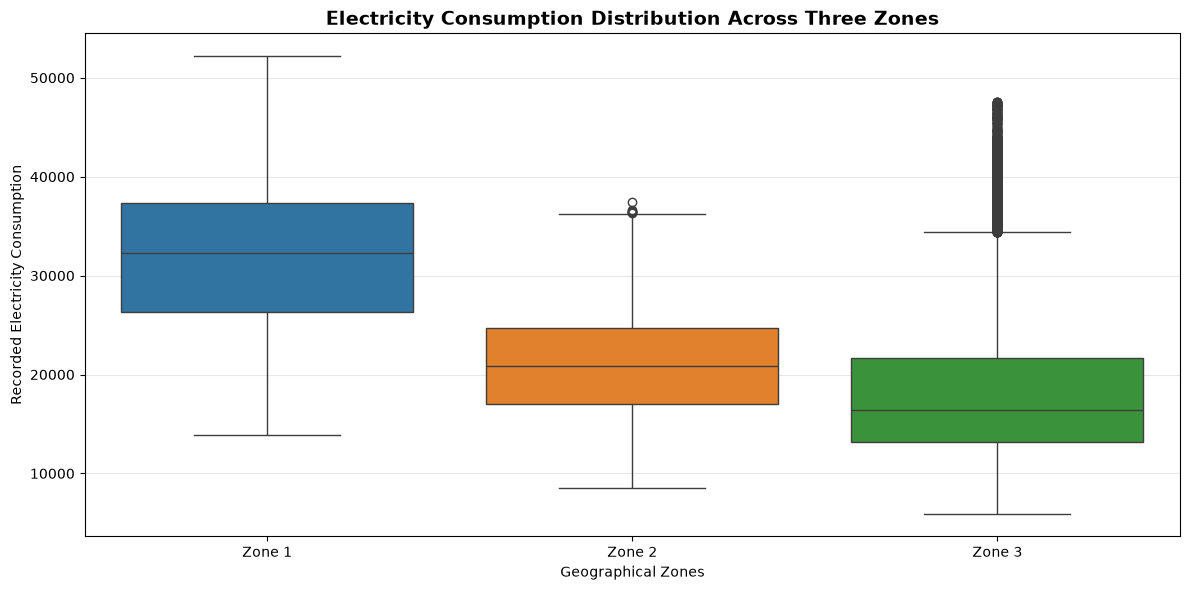

In [48]:
# Select electricity consumption columns
consumption_columns = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"]

# Create boxplots for the three zones
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=pc_analysis[consumption_columns])

plt.title(
    "Electricity Consumption Distribution Across Three Zones",
    fontsize=14,
    fontweight="bold")

plt.xlabel("Geographical Zones")
plt.ylabel("Recorded Electricity Consumption")

plt.xticks(
    ticks=[0, 1, 2],
    labels=["Zone 1", "Zone 2", "Zone 3"])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

#### Boxplot Interpretation

The boxplot comparison indicates that Zone 3 contains the most prominent extreme high-consumption observations.

Although Zone 3 has the lowest median recorded consumption, its upper extreme values are comparatively high.

This suggests that typical consumption levels and peak-demand behaviour differ across geographical zones.

No observations were removed or modified because extreme readings may represent genuine demand events rather than data-quality errors.

### ==========================================
## INVESTIGATE ZONE 3 PEAK OBSERVATIONS
### ==========================================

In [49]:
zone3_peaks = (pc_analysis[["Datetime", "PowerConsumption_Zone3"]]
.nlargest(10, "PowerConsumption_Zone3").reset_index(drop=True))

display(zone3_peaks)

,Datetime,PowerConsumption_Zone3
0,2017-07-24 20:10:00,47598.32636
1,2017-07-27 20:10:00,47598.32636
2,2017-07-26 20:00:00,47580.25105
3,2017-07-26 20:10:00,47507.94979
4,2017-07-26 20:20:00,47441.67364
5,2017-07-27 20:20:00,47435.64854
6,2017-07-24 20:00:00,47429.62343
7,2017-07-24 20:20:00,47405.52301
8,2017-07-26 19:50:00,47291.04603
9,2017-07-23 20:10:00,47278.99582


### ==========================================
## CROSS-ZONE PEAK INVESTIGATION
### ==========================================

In [50]:
# Get timestamps of the 10 highest Zone 3 observations
peak_timestamps = zone3_peaks["Datetime"]

# Retrieve consumption across all three zones
cross_zone_peaks = (pc_analysis[pc_analysis["Datetime"].isin(peak_timestamps)][
        ["Datetime",
         "PowerConsumption_Zone1",
         "PowerConsumption_Zone2",
         "PowerConsumption_Zone3"
        ]]
    .sort_values("Datetime")
    .reset_index(drop=True))

display(cross_zone_peaks)

,Datetime,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-07-23 20:10:00,47700.19934,31158.22785,47278.99582
1,2017-07-24 20:00:00,50755.61462,35008.86076,47429.62343
2,2017-07-24 20:10:00,51540.19934,35069.62025,47598.32636
3,2017-07-24 20:20:00,51533.82060,34974.68354,47405.52301
4,2017-07-26 19:50:00,49505.38206,34594.93671,47291.04603
5,2017-07-26 20:00:00,50474.95017,34731.64557,47580.25105
6,2017-07-26 20:10:00,50685.44850,34651.89873,47507.94979
7,2017-07-26 20:20:00,50800.26578,34651.89873,47441.67364
8,2017-07-27 20:10:00,51208.50498,34868.35443,47598.32636
9,2017-07-27 20:20:00,51297.80731,34674.68354,47435.64854


### ==========================================
## ZONE CONSUMPTION COMPARISON
### ==========================================


In [51]:
consumption_columns = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"]

zone_summary = pc_analysis[consumption_columns].agg(
    ["mean", "median", "min", "max", "std"]).T

zone_summary = zone_summary.round(2)

zone_summary.index = [
    "Zone 1",
    "Zone 2",
    "Zone 3"]

display(zone_summary)

,mean,median,min,max,std
Zone 1,32344.97,32265.92,13895.70,52204.40,7130.56
Zone 2,21042.51,20823.17,8560.08,37408.86,5201.47
Zone 3,17835.41,16415.12,5935.17,47598.33,6622.17


#### Electricity Consumption Comparison Across Zones

The descriptive analysis identified differences in recorded electricity consumption across the three geographical zones.

Key findings:

1. Zone 1 recorded the highest average consumption (32,344.97).
2. Zone 3 recorded the lowest average consumption (17,835.41).
3. Zone 1 exhibited the highest absolute variability, with a standard deviation of 7,130.56.
4. Zone 3 recorded a maximum value of 47,598.33 despite having the lowest average consumption.
5. Zone 3's mean exceeded its median, suggesting an influence from higher consumption observations.

### Business Implications

Zone 1 should receive attention when assessing overall electricity demand, while Zone 3 warrants further investigation into peak-demand behaviour.

These findings are descriptive and do not establish differences in energy efficiency or infrastructure adequacy. Additional information about population, customer numbers and installed capacity would be required for those assessments.

No observations were removed during this analysis.

### ==========================================
## TEMPORAL FEATURE ENGINEERING
### ==========================================

In [52]:
# Extract year
pc_analysis["Year"] = pc_analysis["Datetime"].dt.year

# Extract month
pc_analysis["Month"] = pc_analysis["Datetime"].dt.month

# Extract month name
pc_analysis["Month_Name"] = pc_analysis["Datetime"].dt.month_name()

# Extract day
pc_analysis["Day"] = pc_analysis["Datetime"].dt.day

# Extract hour
pc_analysis["Hour"] = pc_analysis["Datetime"].dt.hour

# Extract day of the week
pc_analysis["Day_of_Week"] = pc_analysis["Datetime"].dt.dayofweek + 1

# Extract day name
pc_analysis["Day_Name"] = pc_analysis["Datetime"].dt.day_name()

# Identify weekends
pc_analysis["Is_Weekend"] = (pc_analysis["Day_of_Week"] >= 6)

# Display the newly created features
display(pc_analysis[
        ["Datetime", "Year", "Month", "Month_Name", "Day", "Hour", "Day_of_Week", "Day_Name", "Is_Weekend"]
    ].head(10))

C:\Users\enoch\AppData\Local\Temp\ipykernel_17808\3079020730.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  pc_analysis["Day_of_Week"] = pc_analysis["Datetime"].dt.dayofweek + 1


,Datetime,Year,Month,Month_Name,Day,Hour,Day_of_Week,Day_Name,Is_Weekend
0,2017-01-01 00:00:00,2017,1,January,1,0,7,Sunday,True
1,2017-01-01 00:10:00,2017,1,January,1,0,7,Sunday,True
2,2017-01-01 00:20:00,2017,1,January,1,0,7,Sunday,True
3,2017-01-01 00:30:00,2017,1,January,1,0,7,Sunday,True
4,2017-01-01 00:40:00,2017,1,January,1,0,7,Sunday,True
5,2017-01-01 00:50:00,2017,1,January,1,0,7,Sunday,True
6,2017-01-01 01:00:00,2017,1,January,1,1,7,Sunday,True
7,2017-01-01 01:10:00,2017,1,January,1,1,7,Sunday,True
8,2017-01-01 01:20:00,2017,1,January,1,1,7,Sunday,True
9,2017-01-01 01:30:00,2017,1,January,1,1,7,Sunday,True


### ==========================================
## TEMPORAL FEATURE VALIDATION
### ==========================================

In [53]:
temporal_columns = ["Year", "Month", "Month_Name", "Day", "Hour", "Day_of_Week", "Day_Name","Is_Weekend"]

print("TEMPORAL FEATURE VALIDATION")

print("\nUnique years:")
print(sorted(pc_analysis["Year"].unique()))

print("\nUnique months:")
print(sorted(pc_analysis["Month"].unique()))

print("\nUnique hours:")
print(sorted(pc_analysis["Hour"].unique()))

print("\nDays of the week:")
print(pc_analysis[["Day_of_Week", "Day_Name"]].drop_duplicates().sort_values("Day_of_Week"))

print("\nWeekend distribution:")
print(pc_analysis["Is_Weekend"].value_counts())

print("\nMissing values in temporal features:")
print(pc_analysis[temporal_columns].isnull().sum())

TEMPORAL FEATURE VALIDATION

Unique years:
[np.int32(2017)]

Unique months:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Unique hours:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]

Days of the week:
     Day_of_Week   Day_Name
144            1     Monday
288            2    Tuesday
432            3  Wednesday
576            4   Thursday
720            5     Friday
864            6   Saturday
0              7     Sunday

Weekend distribution:
Is_Weekend
False    37440
True     14976
Name: count, dtype: int64

Missing values in temporal features:
Year           0
Month          0
Month_Name     0


### ==========================================
## CREATE DATE COLUMN
### ==========================================

In [54]:
# Extract date without the time component
pc_analysis["Date"] = pc_analysis["Datetime"].dt.date

# Verify the new column
print("DATE COLUMN CREATED")

display(pc_analysis[["Datetime", "Date"]].head(10))

print("\nDATE DATA TYPE:")
print(pc_analysis["Date"].dtype)

print("\nNUMBER OF UNIQUE DATES:")
print(pc_analysis["Date"].nunique())

DATE COLUMN CREATED


,Datetime,Date
0,2017-01-01 00:00:00,2017-01-01
1,2017-01-01 00:10:00,2017-01-01
2,2017-01-01 00:20:00,2017-01-01
3,2017-01-01 00:30:00,2017-01-01
4,2017-01-01 00:40:00,2017-01-01
5,2017-01-01 00:50:00,2017-01-01
6,2017-01-01 01:00:00,2017-01-01
7,2017-01-01 01:10:00,2017-01-01
8,2017-01-01 01:20:00,2017-01-01
9,2017-01-01 01:30:00,2017-01-01



DATE DATA TYPE:
object

NUMBER OF UNIQUE DATES:
364


### ==========================================
## STANDARDISE DATE DATA TYPE
### ==========================================

In [55]:


pc_analysis["Date"] = pd.to_datetime(pc_analysis["Date"])

# Verify the data type
print("DATE DATA TYPE:")
print(pc_analysis["Date"].dtype)

# Verify unique dates
print("\nUNIQUE DATES:")
print(pc_analysis["Date"].nunique())

# Preview
display(pc_analysis[["Datetime", "Date"]].head(10))

DATE DATA TYPE:
datetime64[s]

UNIQUE DATES:
364


,Datetime,Date
0,2017-01-01 00:00:00,2017-01-01
1,2017-01-01 00:10:00,2017-01-01
2,2017-01-01 00:20:00,2017-01-01
3,2017-01-01 00:30:00,2017-01-01
4,2017-01-01 00:40:00,2017-01-01
5,2017-01-01 00:50:00,2017-01-01
6,2017-01-01 01:00:00,2017-01-01
7,2017-01-01 01:10:00,2017-01-01
8,2017-01-01 01:20:00,2017-01-01
9,2017-01-01 01:30:00,2017-01-01


### ==========================================
## FINAL DATASET INSPECTION
### ==========================================

In [56]:
print("WORKING DATASET SHAPE:")
print(pc_analysis.shape)

print("\nALL COLUMN NAMES:")
print(pc_analysis.columns.tolist())

print("\nDATA TYPES:")
print(pc_analysis.dtypes)

print("\nMISSING VALUES:")
print(pc_analysis.isnull().sum().sum())

print("\nFIRST FIVE RECORDS:")
display(pc_analysis.head())

WORKING DATASET SHAPE:
(52416, 18)

ALL COLUMN NAMES:
['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3', 'Year', 'Month', 'Month_Name', 'Day', 'Hour', 'Day_of_Week', 'Day_Name', 'Is_Weekend', 'Date']

DATA TYPES:
Datetime                  datetime64[us]
Temperature                      float64
Humidity                         float64
WindSpeed                        float64
GeneralDiffuseFlows              float64
DiffuseFlows                     float64
PowerConsumption_Zone1           float64
PowerConsumption_Zone2           float64
PowerConsumption_Zone3           float64
Year                               int32
Month                              int32
Month_Name                           str
Day                                int32
Hour                               int32
Day_of_Week                        int32
Day_Name                             str
Is_Weekend  

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Month_Name,Day,Hour,Day_of_Week,Day_Name,Is_Weekend,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,January,1,0,7,Sunday,True,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,January,1,0,7,Sunday,True,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,January,1,0,7,Sunday,True,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,January,1,0,7,Sunday,True,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,January,1,0,7,Sunday,True,2017-01-01


In [57]:
from pathlib import Path

# Create the processed-data folder if it does not exist
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the prepared dataset
output_path = processed_dir / "morocco_electricity_prepared.csv"

pc_analysis.to_csv(output_path, index=False)

# Confirm successful saving
print("Prepared dataset saved successfully.")
print("File location:", output_path)
print("File exists:", output_path.exists())
print("Rows saved:", len(pc_analysis))

Prepared dataset saved successfully.
File location: ..\data\processed\morocco_electricity_prepared.csv
File exists: True
Rows saved: 52416


#### ELECTRICITY CONSUMPTION ANALYSIS

##### Overall Consumption Profile Across the Three Zones

This section examines the distribution of recorded electricity consumption across the three geographical zones. Descriptive statistics will be used to compare typical consumption levels, observed extremes and variability.

### ==========================================
## OVERALL CONSUMPTION PROFILE BY ZONE
### ==========================================

In [58]:
zone_columns = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]

zone_summary = pc_analysis[zone_columns].agg(["mean", "median", "min", "max", "std"]).T

zone_summary = zone_summary.rename(columns={
    "mean": "Average",
    "median": "Median",
    "min": "Minimum",
    "max": "Maximum",
    "std": "Standard Deviation"})

zone_summary.index = ["Zone 1", "Zone 2", "Zone 3"]

display(zone_summary.round(2))

,Average,Median,Minimum,Maximum,Standard Deviation
Zone 1,32344.97,32265.92,13895.70,52204.40,7130.56
Zone 2,21042.51,20823.17,8560.08,37408.86,5201.47
Zone 3,17835.41,16415.12,5935.17,47598.33,6622.17


### ==========================================
## AVERAGE CONSUMPTION BY ZONE
### ==========================================

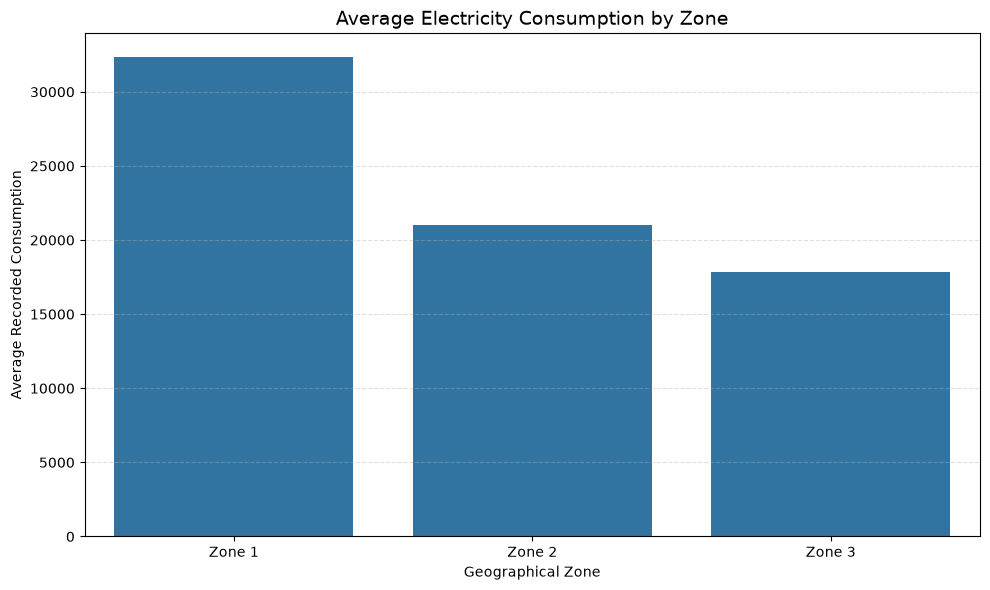

In [59]:
# Calculate average recorded consumption by zone
zone_averages = pc_analysis[zone_columns].mean()

# Prepare labels
zone_averages.index = ["Zone 1", "Zone 2", "Zone 3"]

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    x=zone_averages.index,
    y=zone_averages.values
)

plt.title("Average Electricity Consumption by Zone", fontsize=14)
plt.xlabel("Geographical Zone")
plt.ylabel("Average Recorded Consumption")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Interpretation

The visualisation indicates differences in average recorded electricity consumption across the three geographical zones. Zone 1 records the highest average, followed by Zone 2, while Zone 3 records the lowest.

These differences suggest that electricity demand is not evenly distributed across the three zones. However, the chart alone does not explain the reasons behind these differences. Further analysis of temporal patterns and environmental variables is required before drawing operational conclusions.

**Business relevance:** Understanding the distribution of recorded consumption can help energy planners identify zones that may require closer monitoring and further investigation when developing demand-management strategies.

### ==========================================
## HOURLY CONSUMPTION ANALYSIS
### ==========================================

In [60]:
hourly_consumption = pc_analysis.groupby("Hour")[zone_columns].mean()

hourly_consumption.index.name = "Hour"

display(hourly_consumption.round(2))

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


### ==========================================
## HOURLY CONSUMPTION TREND
### ==========================================

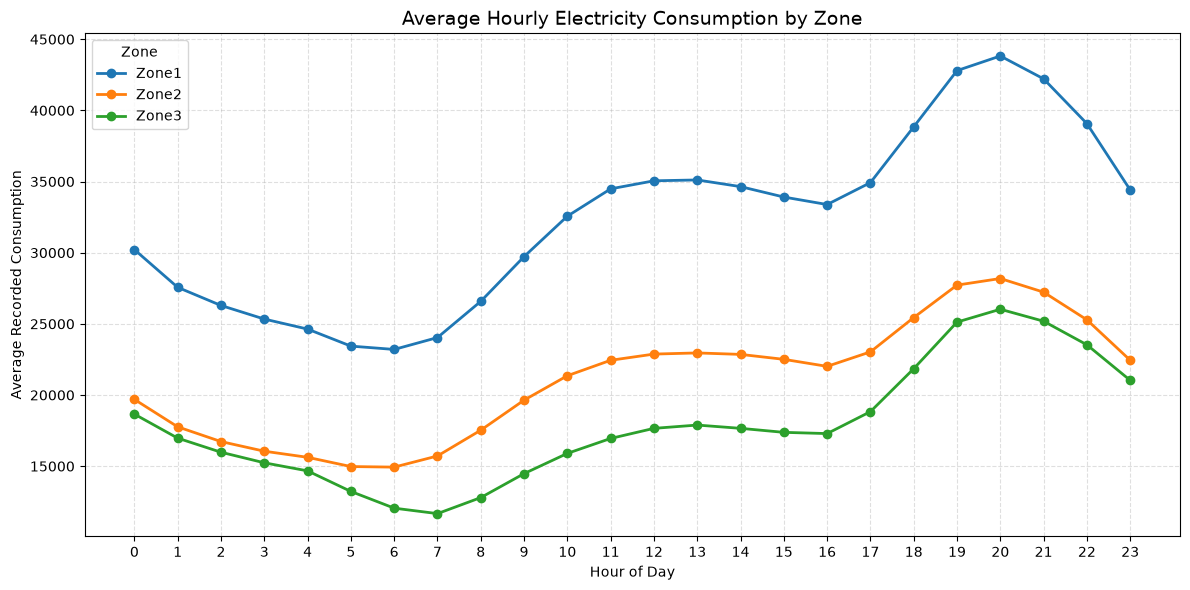

In [61]:
plt.figure(figsize=(12, 6))

for zone in hourly_consumption.columns:
    plt.plot(
        hourly_consumption.index,
        hourly_consumption[zone],
        marker="o",
        linewidth=2,
        label=zone.replace("PowerConsumption_", "").replace("_", " ")
    )

plt.title("Average Hourly Electricity Consumption by Zone", fontsize=14)
plt.xlabel("Hour of Day")
plt.ylabel("Average Recorded Consumption")
plt.xticks(range(24))
plt.legend(title="Zone")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### ==========================================
## PEAK AND LOWEST HOURLY CONSUMPTION
### ==========================================

In [62]:
hourly_peak_low = pd.DataFrame({
    "Peak Hour": hourly_consumption.idxmax(),
    "Peak Average": hourly_consumption.max(),
    "Lowest Hour": hourly_consumption.idxmin(),
    "Lowest Average": hourly_consumption.min()
})

hourly_peak_low.index = ["Zone 1", "Zone 2", "Zone 3"]

display(hourly_peak_low.round(2))

,Peak Hour,Peak Average,Lowest Hour,Lowest Average
Zone 1,20,43822.59,6,23203.60
Zone 2,20,28186.91,6,14934.70
Zone 3,20,26027.61,7,11667.86


#### Interpretation of Hourly Consumption Patterns

The hourly analysis reveals a consistent evening peak across all three geographical zones. Zone 1, Zone 2 and Zone 3 all record their highest average consumption at 20:00 (8 PM).

The lowest average readings occur at 06:00 (6 AM) for Zones 1 and 2, and 07:00 (7 AM) for Zone 3.

Zone 1 records the highest average reading at both its peak and lowest hours. The shared evening peak indicates a similar daily consumption pattern across the three zones.

**Business relevance:** The consistent evening peak provides a useful signal for energy planners when reviewing peak-period demand, scheduling operational monitoring and assessing potential demand-management strategies. However, further investigation is required to establish the causes of this pattern.

### ==========================================
## DAILY CONSUMPTION ANALYSIS
### ==========================================

In [63]:
daily_consumption = pc_analysis.groupby("Date")[zone_columns].mean()

daily_consumption.index.name = "Date"

print("Daily consumption dataset:")
print("Number of days:", len(daily_consumption))

display(daily_consumption.head())

Daily consumption dataset:
Number of days: 364


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Date,,,
2017-01-01,28465.232067,17737.791287,17868.795181
2017-01-02,28869.493671,19557.725431,17820.763053
2017-01-03,30562.447257,20057.269504,17620.803213
2017-01-04,30689.831224,20102.077001,17673.694779
2017-01-05,30802.911393,20033.941237,17664.176707


### ==========================================
## DAILY CONSUMPTION TRENDS
### ==========================================

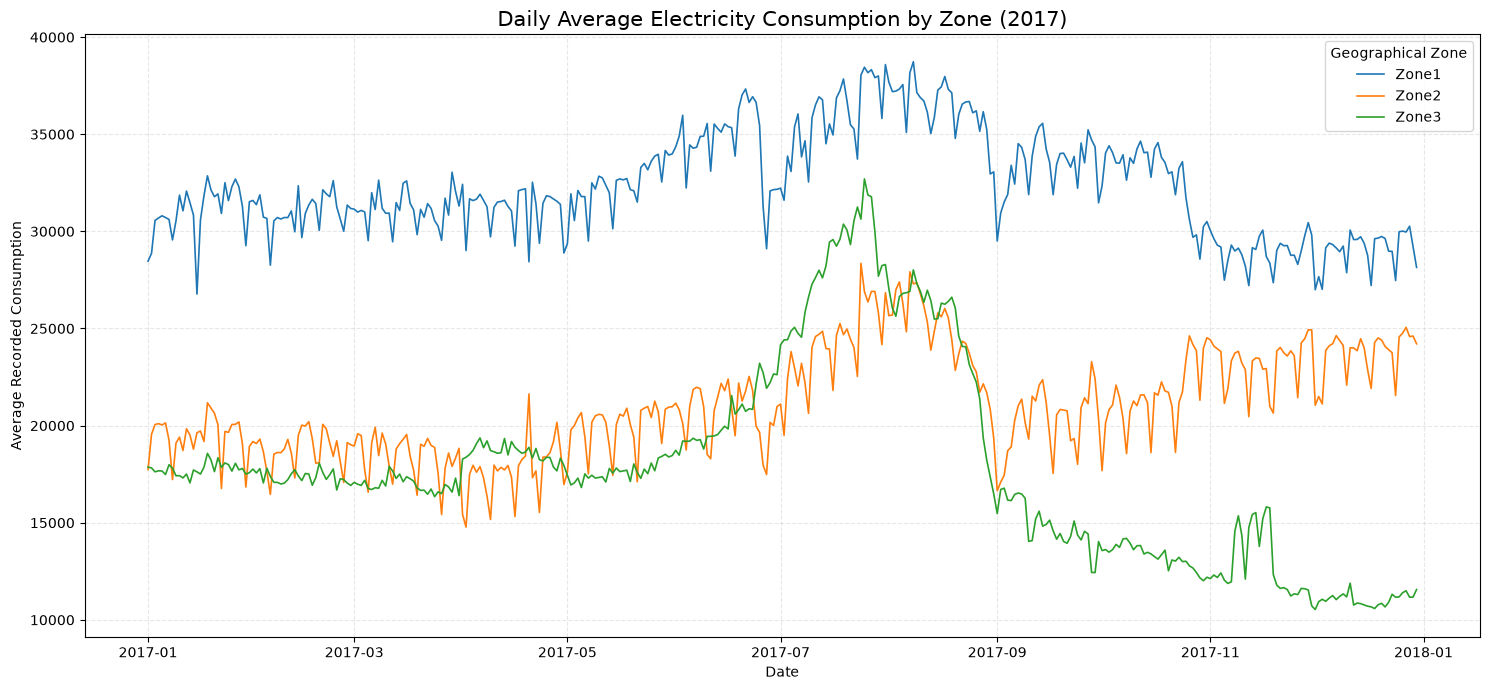

In [64]:
plt.figure(figsize=(15, 7))

for zone in daily_consumption.columns:
    plt.plot(
        daily_consumption.index,
        daily_consumption[zone],
        linewidth=1.2,
        label=zone.replace("PowerConsumption_", "").replace("_", " ")
    )

plt.title("Daily Average Electricity Consumption by Zone (2017)", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Average Recorded Consumption")
plt.legend(title="Geographical Zone")
plt.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### ==========================================
## HIGHEST AND LOWEST DAILY CONSUMPTION
### ==========================================

In [65]:
daily_peak_low = pd.DataFrame({
    "Highest Consumption Date": daily_consumption.idxmax(),
    "Highest Daily Average": daily_consumption.max(),
    "Lowest Consumption Date": daily_consumption.idxmin(),
    "Lowest Daily Average": daily_consumption.min()
})

daily_peak_low.index = ["Zone 1", "Zone 2", "Zone 3"]

display(daily_peak_low.round(2))

C:\Users\enoch\AppData\Local\Temp\ipykernel_17808\370228458.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily_peak_low.round(2))


,Highest Consumption Date,Highest Daily Average,Lowest Consumption Date,Lowest Daily Average
Zone 1,2017-08-08,38733.50,2017-01-15,26771.52
Zone 2,2017-07-24,28354.54,2017-04-02,14779.10
Zone 3,2017-07-25,32700.21,2017-12-01,10530.61


#### Interpretation of Daily Consumption Extremes

The daily analysis reveals that the three geographical zones experienced their highest and lowest average recorded consumption on different dates.

Zone 1 recorded its highest daily average on 8 August 2017, while Zones 2 and 3 reached their highest daily averages on 24 and 25 July 2017, respectively.

The lowest daily averages also occurred at different times: 15 January for Zone 1, 2 April for Zone 2 and 1 December for Zone 3.

These differences indicate that daily consumption fluctuations are not perfectly aligned across the three zones.

**Business relevance:** Identifying the dates associated with unusually high or low consumption can help energy planners investigate demand fluctuations and assess whether additional monitoring or operational planning is necessary. These observations alone do not establish the causes of the fluctuations.

### ==========================================
## WEEKLY PATTERN: DAY-OF-WEEK ANALYSIS
### ==========================================

In [66]:
weekly_consumption = (pc_analysis.groupby("Day_Name")[zone_columns].mean())

# Arrange days in calendar order
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekly_consumption = weekly_consumption.reindex(day_order)

display(weekly_consumption.round(2))

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_Name,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


### ==========================================
## WEEKLY CONSUMPTION VISUALISATION
### ==========================================

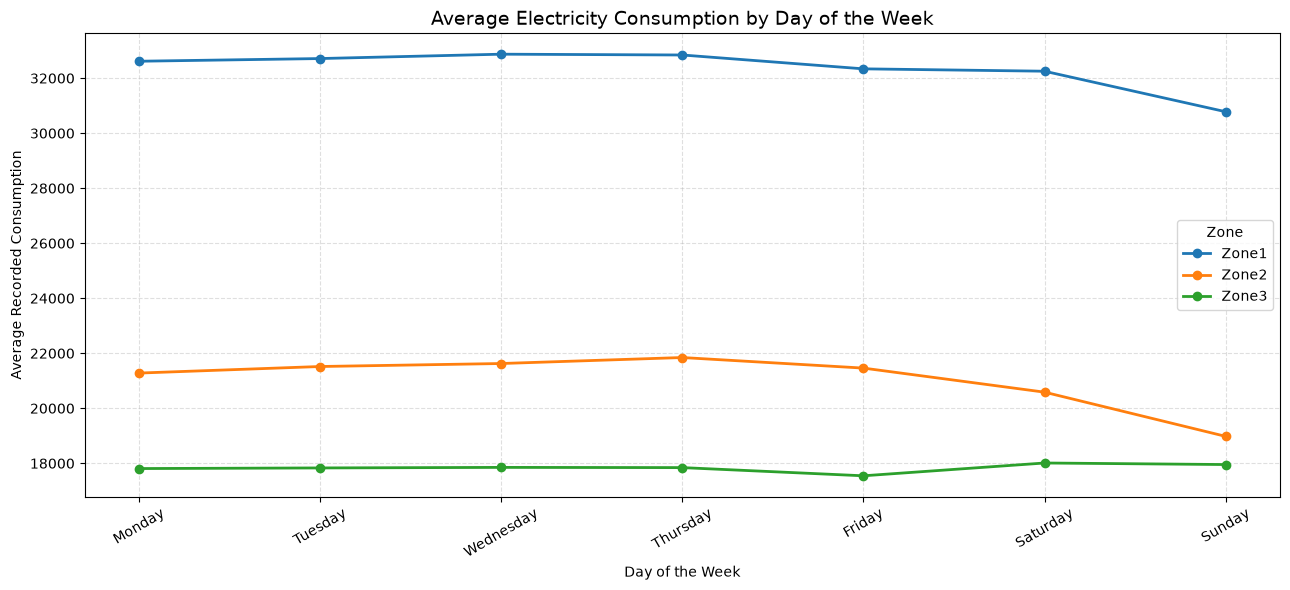

In [67]:
plt.figure(figsize=(13, 6))

for zone in weekly_consumption.columns:
    plt.plot(
        weekly_consumption.index,
        weekly_consumption[zone],
        marker="o",
        linewidth=2,
        label=zone.replace("PowerConsumption_", "").replace("_", " ")
    )

plt.title("Average Electricity Consumption by Day of the Week", fontsize=14)
plt.xlabel("Day of the Week")
plt.ylabel("Average Recorded Consumption")
plt.xticks(rotation=30)
plt.legend(title="Zone")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

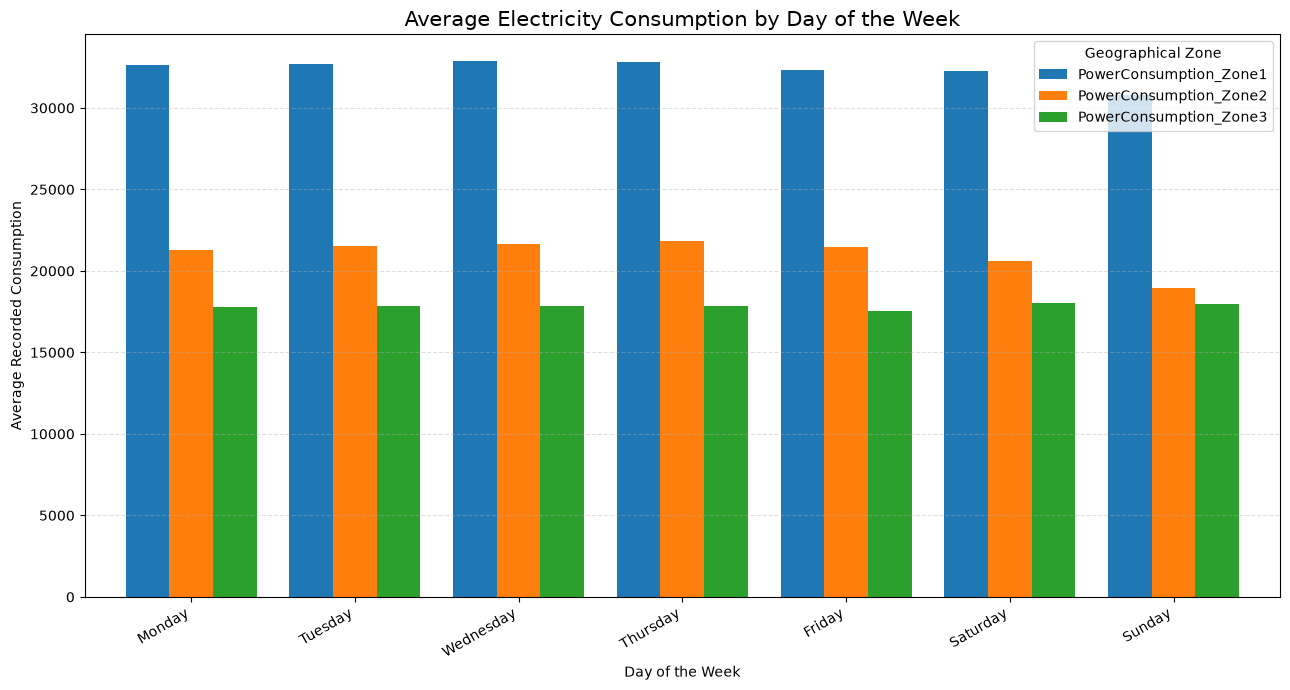

In [68]:
# ==========================================
# WEEKLY CONSUMPTION BAR CHART
# ==========================================

weekly_consumption.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Average Electricity Consumption by Day of the Week", fontsize=15)

plt.xlabel("Day of the Week")
plt.ylabel("Average Recorded Consumption")

plt.xticks(rotation=30, ha="right")
plt.legend(title="Geographical Zone")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Interpretation of Weekly Consumption Patterns

The weekly analysis reveals differences in average recorded electricity consumption across the three geographical zones.

Zone 1 records its highest average on Wednesday and its lowest on Sunday. Zone 2 records its highest average on Thursday and its lowest on Sunday. In contrast, Zone 3 records its highest average on Saturday and its lowest on Friday.

The results suggest that weekly consumption patterns vary across the geographical zones, with Sunday showing notably lower averages in Zones 1 and 2.

**Business relevance:** Understanding differences between weekdays and weekends can support demand monitoring and operational planning. Further investigation is needed to determine the factors responsible for these patterns.

### ==========================================
## WEEKDAY VS WEEKEND ANALYSIS
### ==========================================

In [69]:
weekday_weekend = pc_analysis.groupby("Is_Weekend")[zone_columns].mean()

weekday_weekend.index = ["Weekday", "Weekend"]

display(weekday_weekend.round(2))

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Weekday,32676.34,21546.45,17776.37
Weekend,31516.56,19782.67,17983.01


#### Interpretation of Weekday and Weekend Consumption

The comparison reveals different weekday and weekend consumption patterns across the three geographical zones.

Zones 1 and 2 record higher average consumption during weekdays than weekends. Zone 3, however, records a slightly higher weekend average than weekday average.

Zone 2 shows the largest difference between weekday and weekend averages, while Zone 3 shows a relatively small difference.

**Business relevance:** These differences can help energy planners understand how demand varies across working days and weekends. They may also support more targeted demand-monitoring strategies across the zones. However, the analysis does not establish the underlying causes of these differences.

### ==========================================
## MONTHLY CONSUMPTION ANALYSIS
### ==========================================

In [70]:
monthly_consumption = pc_analysis.groupby("Month")[zone_columns].mean()

month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

monthly_consumption.index = month_order
monthly_consumption.index.name = "Month"

display(monthly_consumption.round(2))

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
January,31032.49,19394.44,17746.10
February,30985.75,18787.79,17335.00
March,31155.17,18457.94,16947.69
April,31169.77,17633.97,18593.17
May,32396.01,19977.29,17621.10
June,34605.54,20670.93,20430.94
July,35831.55,24147.89,28194.11
August,36435.19,24656.22,24648.89
September,33396.68,20180.43,14922.80


#### Interpretation of Monthly Consumption Patterns

The monthly analysis reveals distinct consumption patterns across the three geographical zones.

Zone 1 and Zone 2 record their highest average consumption in August, while Zone 3 reaches its highest average in July.

Zone 1 records its lowest monthly average in November, Zone 2 in April, and Zone 3 in December.

A particularly notable pattern occurs in Zone 3, where average recorded consumption increases substantially between April and July before declining through December.

**Business relevance:** Monthly consumption patterns can help energy planners identify periods of increased or reduced demand, support seasonal monitoring and inform operational planning. However, the observed patterns alone do not establish their causes.

### ==========================================
## MONTHLY CONSUMPTION
### ==========================================

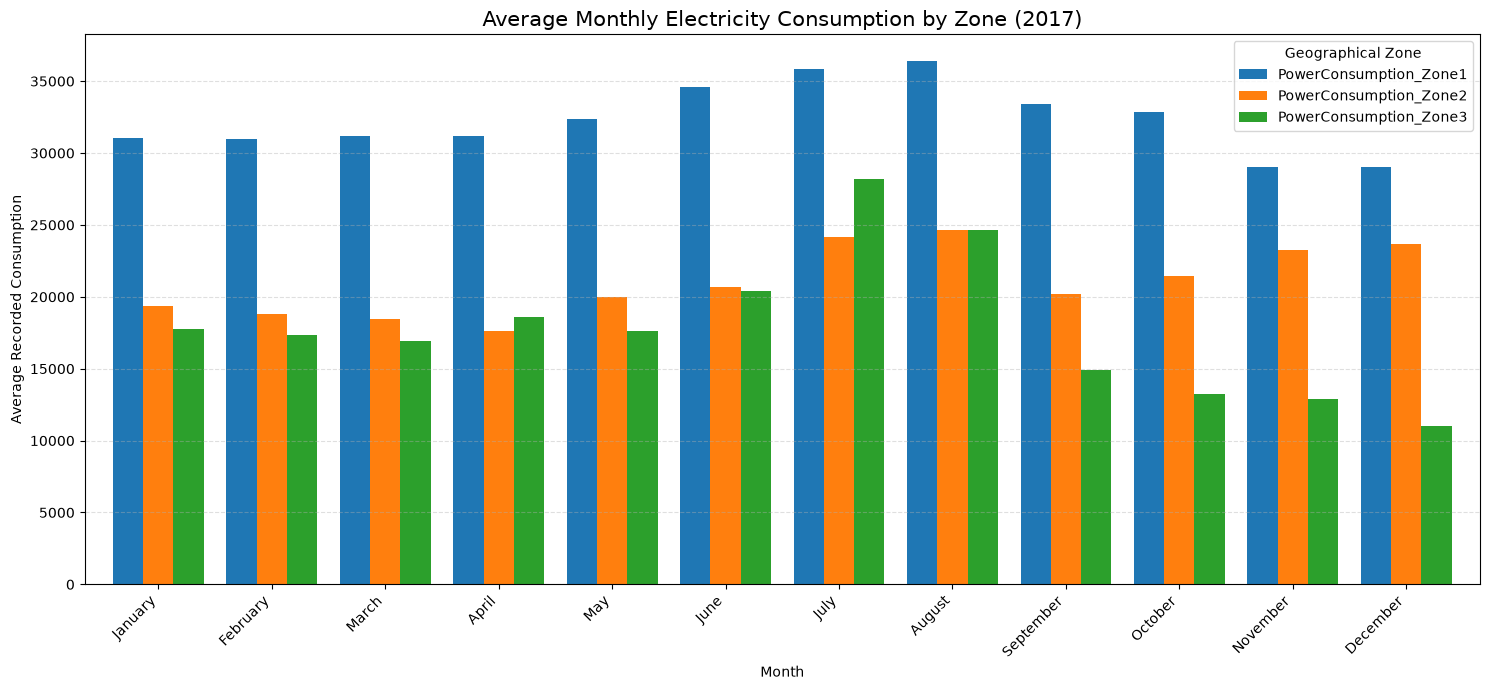

In [71]:
monthly_consumption.plot(kind="bar",
    figsize=(15, 7),
    width=0.8)

plt.title("Average Monthly Electricity Consumption by Zone (2017)",
    fontsize=15)

plt.xlabel("Month")
plt.ylabel("Average Recorded Consumption")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Geographical Zone")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Monthly Consumption Visualisation

The grouped bar chart highlights differences in monthly average recorded consumption across the three geographical zones.

Zone 1 and Zone 2 show their highest monthly averages in August, while Zone 3 peaks in July. Zone 3 also demonstrates a marked decline towards the end of the year.

The visualisation reinforces the importance of analysing each geographical zone independently rather than assuming that all zones experience identical demand patterns.

### ==========================================
## HIGHEST AND LOWEST MONTHLY AVERAGES
### ==========================================

In [72]:
monthly_peak_low = pd.DataFrame({
    "Highest Month": monthly_consumption.idxmax(),
    "Highest Average": monthly_consumption.max(),
    "Lowest Month": monthly_consumption.idxmin(),
    "Lowest Average": monthly_consumption.min()
})

display(monthly_peak_low.round(2))

,Highest Month,Highest Average,Lowest Month,Lowest Average
PowerConsumption_Zone1,August,36435.19,November,29002.11
PowerConsumption_Zone2,August,24656.22,April,17633.97
PowerConsumption_Zone3,July,28194.11,December,11044.81


#### Monthly Peak and Lowest Consumption Findings

The analysis confirms that Zone 1 and Zone 2 reach their highest monthly average recorded consumption in August, while Zone 3 peaks in July.

The lowest monthly averages occur in November for Zone 1, April for Zone 2 and December for Zone 3.

These differences highlight the importance of zone-specific monitoring and planning rather than applying one seasonal demand assumption across all geographical zones.

### ==========================================
## MONTHLY CONSUMPTION TREND
### ==========================================

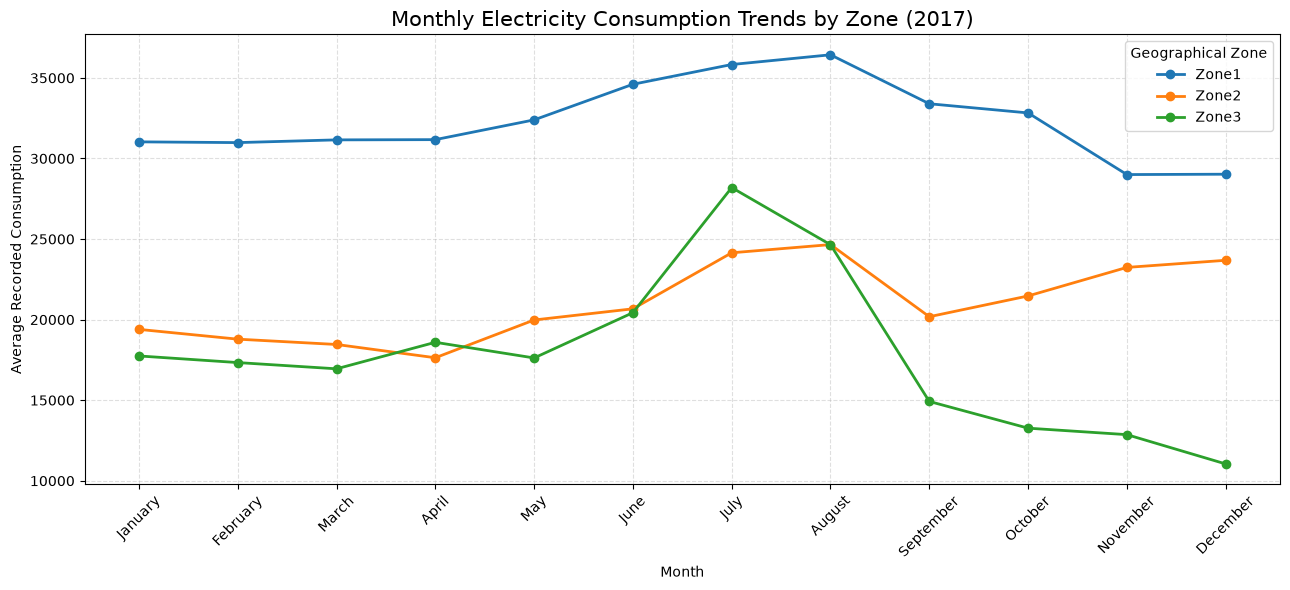

In [73]:
plt.figure(figsize=(13, 6))

for zone in monthly_consumption.columns:
    plt.plot(
        monthly_consumption.index,
        monthly_consumption[zone],
        marker="o",
        linewidth=2,
        label=zone.replace("PowerConsumption_", "").replace("_", " ")
    )

plt.title("Monthly Electricity Consumption Trends by Zone (2017)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Average Recorded Consumption")
plt.xticks(rotation=45)
plt.legend(title="Geographical Zone")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### ==========================================
## ZONE PERCENTAGE CONTRIBUTION
### ==========================================

In [74]:
# Calculate the sum of recorded readings for each zone
zone_totals = pc_analysis[zone_columns].sum()

# Calculate percentage contribution
zone_percentage = (zone_totals / zone_totals.sum()) * 100

# Create comparison table
zone_contribution = pd.DataFrame({
    "Recorded Reading Sum": zone_totals,
    "Percentage Contribution": zone_percentage
})

zone_contribution.index = ["Zone 1", "Zone 2", "Zone 3"]

display(zone_contribution.round(2))

,Recorded Reading Sum,Percentage Contribution
Zone 1,1.695394e+09,45.41
Zone 2,1.102964e+09,29.54
Zone 3,9.348607e+08,25.04


#### Interpretation of Zone Percentage Contributions

Zone 1 accounts for approximately 45.41% of the combined sum of recorded consumption readings, making it the largest contributor among the three zones.

Zone 2 accounts for 29.54%, while Zone 3 accounts for approximately 25.04%.

These results reinforce the earlier finding that Zone 1 has the highest average recorded consumption.

**Business relevance:** The distribution can help energy planners identify which zones account for larger proportions of recorded readings and prioritise further investigation.

### ==========================================
## COMPARATIVE ZONE BOXPLOT
### ==========================================

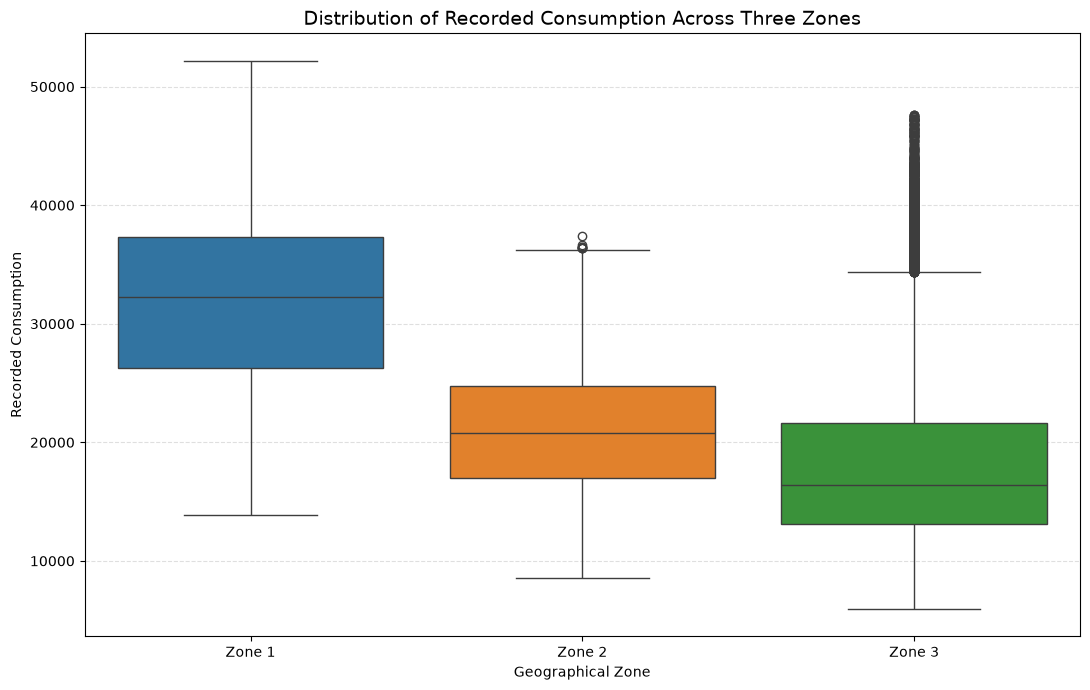

In [75]:
zone_data = pc_analysis[zone_columns].copy()

zone_data.columns = ["Zone 1", "Zone 2", "Zone 3"]

plt.figure(figsize=(11, 7))

sns.boxplot(data=zone_data)

plt.title("Distribution of Recorded Consumption Across Three Zones", fontsize=14)
plt.xlabel("Geographical Zone")
plt.ylabel("Recorded Consumption")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#### Interpretation of Comparative Zone Boxplot

The boxplot compares the distributions of recorded electricity consumption across the three geographical zones.

Zone 1 has the highest median recorded consumption, consistent with its higher average. Zone 3 has the highest maximum observation, demonstrating that its lower average does not prevent it from experiencing comparatively high individual readings.

The boxplot also helps identify differences in variability and potential extreme observations across the zones.

**Business relevance:** Comparing distributions rather than averages alone provides a more complete understanding of consumption behaviour and can help identify zones that warrant further investigation.

### ==========================================
## MONTHLY ZONE COMPARISON HEATMAP
### ==========================================

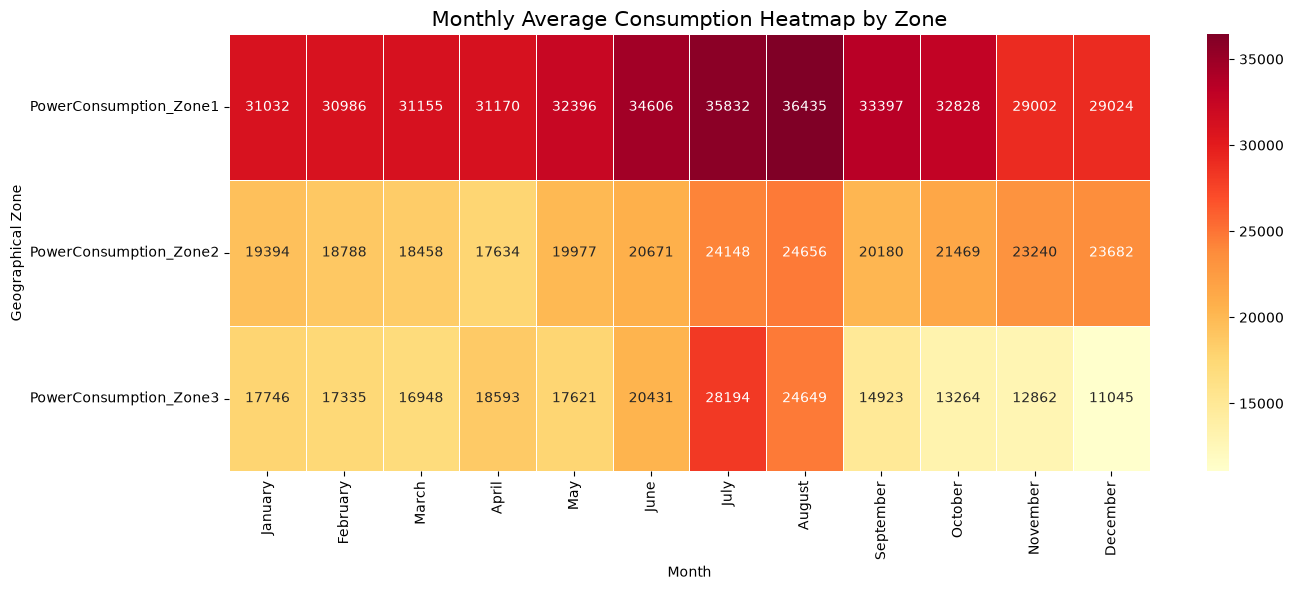

In [76]:
heatmap_data = monthly_consumption.T

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Average Consumption Heatmap by Zone", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Geographical Zone")

plt.tight_layout()
plt.show()

#### Interpretation of Monthly Zone Comparison Heatmap

The heatmap provides a visual comparison of average recorded consumption across the three geographical zones and twelve months.

It highlights differences in the intensity and distribution of recorded consumption throughout the year. Zone 1 generally records higher average readings, while Zone 3 demonstrates more pronounced monthly fluctuations.

The visualisation reinforces the importance of examining each zone independently when evaluating consumption patterns.

**Business relevance:** The heatmap can help energy planners identify periods and geographical zones that may require closer demand monitoring and further investigation.

### ==========================================
## ENVIRONMENTAL RELATIONSHIP ANALYSIS
## ENVIRONMENTAL VARIABLE SUMMARY
## ==========================================

In [77]:
environmental_columns = ["Temperature", "Humidity", "WindSpeed"]

environment_summary = pc_analysis[environmental_columns].describe().T

display(environment_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
Humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
WindSpeed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48


#### Environmental Variable Summary

The environmental variables contain 52,416 observations each, with no missing observations.

Temperature has a mean of 18.81 and a median of 18.78, indicating that the two central measures are closely aligned. Humidity has a mean of 68.26 and a median of 69.86, with a wider range of observed values. Wind speed has a mean of 1.96 but a much lower median of 0.09, indicating a right-skewed distribution influenced by higher readings.

These findings describe the distribution of the recorded environmental variables. Further analysis is required to examine their statistical relationships with electricity consumption. The results should not be interpreted as evidence of causation.

In [78]:
environmental_columns = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]

correlation_columns = environmental_columns + zone_columns

correlation_matrix = pc_analysis[correlation_columns].corr(method="pearson")

display(correlation_matrix.round(2))

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,1.00,-0.46,0.48,0.46,0.20,0.44,0.38,0.49
Humidity,-0.46,1.00,-0.14,-0.47,-0.26,-0.29,-0.29,-0.23
WindSpeed,0.48,-0.14,1.00,0.13,-0.00,0.17,0.15,0.28
GeneralDiffuseFlows,0.46,-0.47,0.13,1.00,0.56,0.19,0.16,0.06
DiffuseFlows,0.20,-0.26,-0.00,0.56,1.00,0.08,0.04,-0.04
PowerConsumption_Zone1,0.44,-0.29,0.17,0.19,0.08,1.00,0.83,0.75
PowerConsumption_Zone2,0.38,-0.29,0.15,0.16,0.04,0.83,1.00,0.57
PowerConsumption_Zone3,0.49,-0.23,0.28,0.06,-0.04,0.75,0.57,1.00


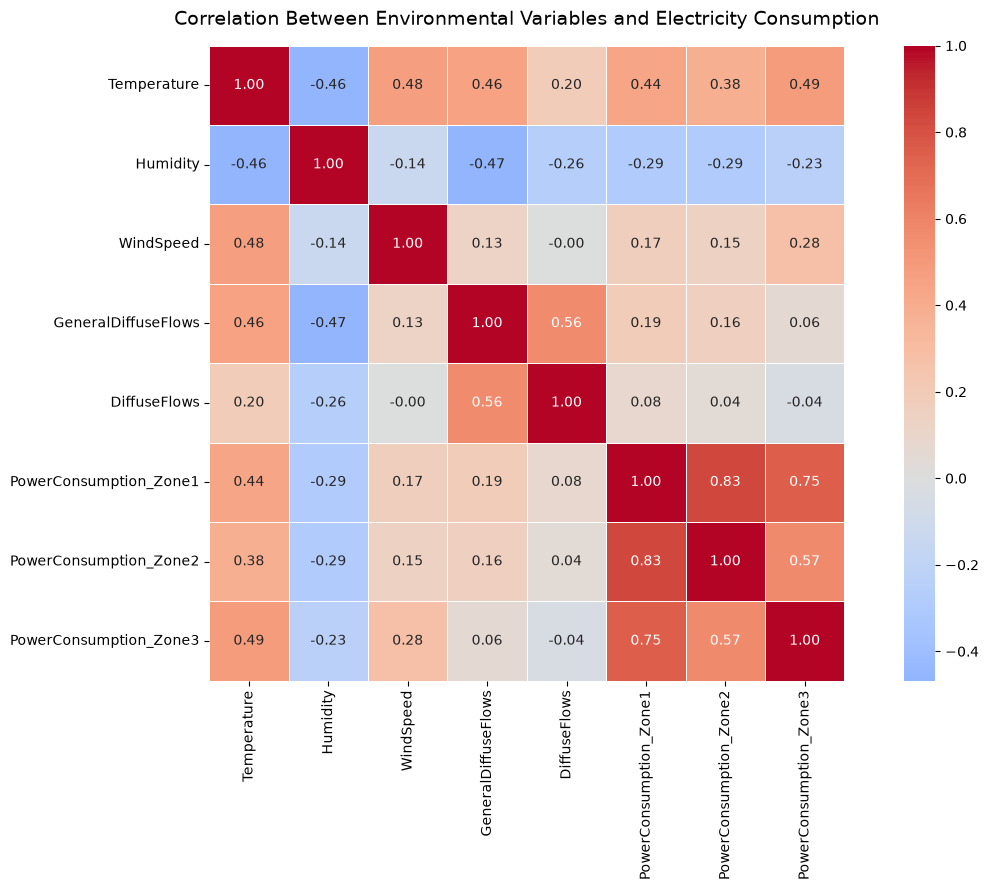

In [79]:
#### Correlation heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5,
    square=True)

plt.title("Correlation Between Environmental Variables and Electricity Consumption",
    fontsize=14,
    pad=15)

plt.tight_layout()
plt.show()

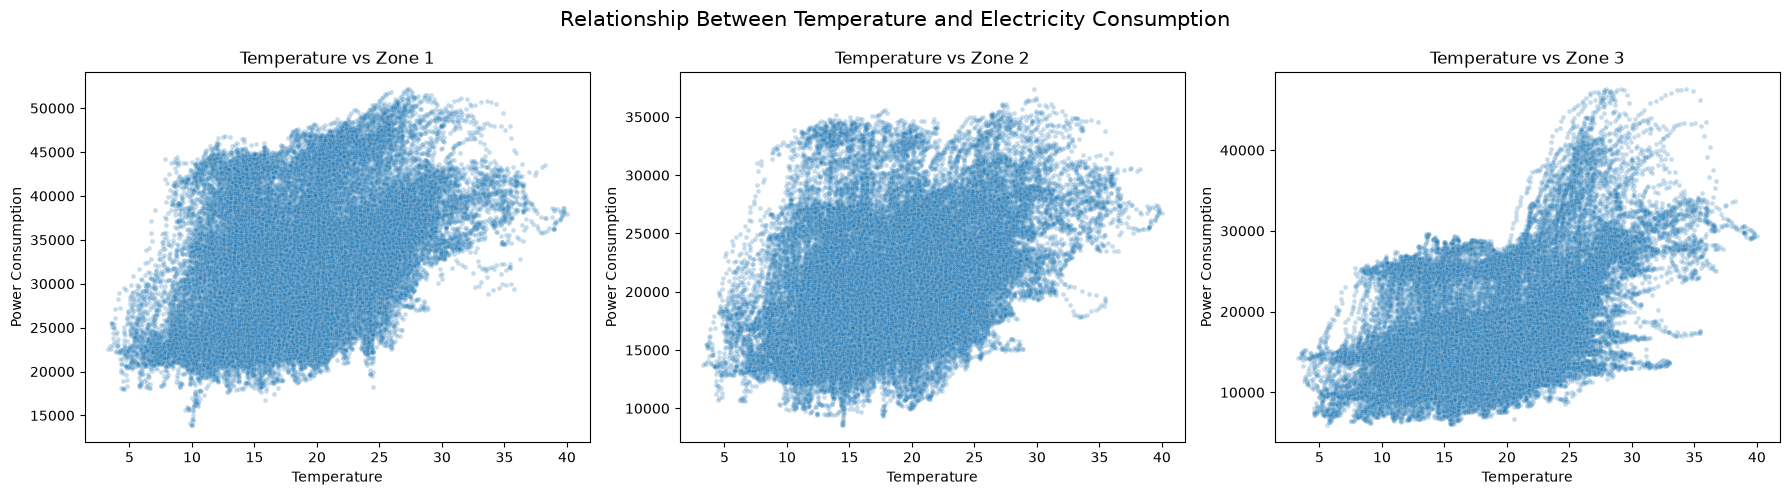

In [80]:
#### Temperature and electricity consumption
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]

zone_labels = ["Zone 1", "Zone 2", "Zone 3"]

for ax, zone, label in zip(axes, zones, zone_labels):
    sns.scatterplot(
        data=pc_analysis,
        x="Temperature",
        y=zone,
        alpha=0.25,
        s=12,
        ax=ax)

    ax.set_title(f"Temperature vs {label}")
    ax.set_xlabel("Temperature")
    ax.set_ylabel("Power Consumption")

plt.suptitle(
    "Relationship Between Temperature and Electricity Consumption",
    fontsize=15)

plt.tight_layout()
plt.show()

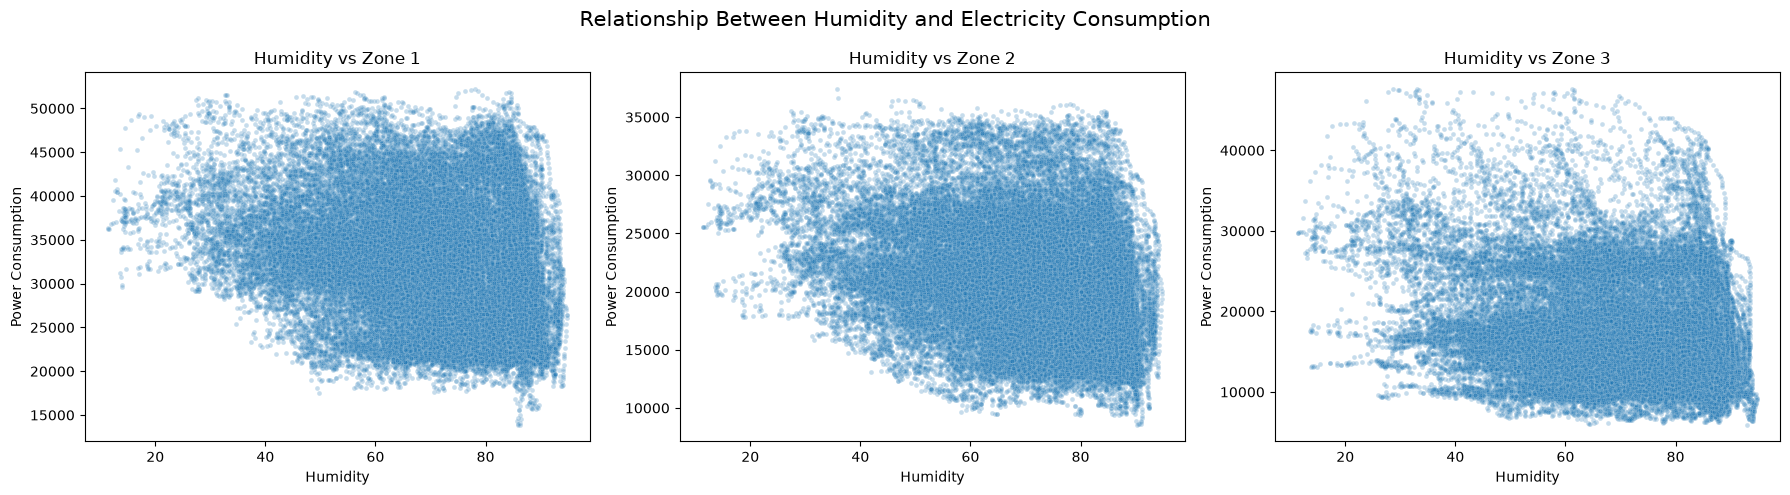

In [81]:
#### Humidity and electricity consumption
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, zone, label in zip(axes, zones, zone_labels):
    sns.scatterplot(
        data=pc_analysis,
        x="Humidity",
        y=zone,
        alpha=0.25,
        s=12,
        ax=ax)

    ax.set_title(f"Humidity vs {label}")
    ax.set_xlabel("Humidity")
    ax.set_ylabel("Power Consumption")

plt.suptitle("Relationship Between Humidity and Electricity Consumption",
    fontsize=15)

plt.tight_layout()
plt.show()

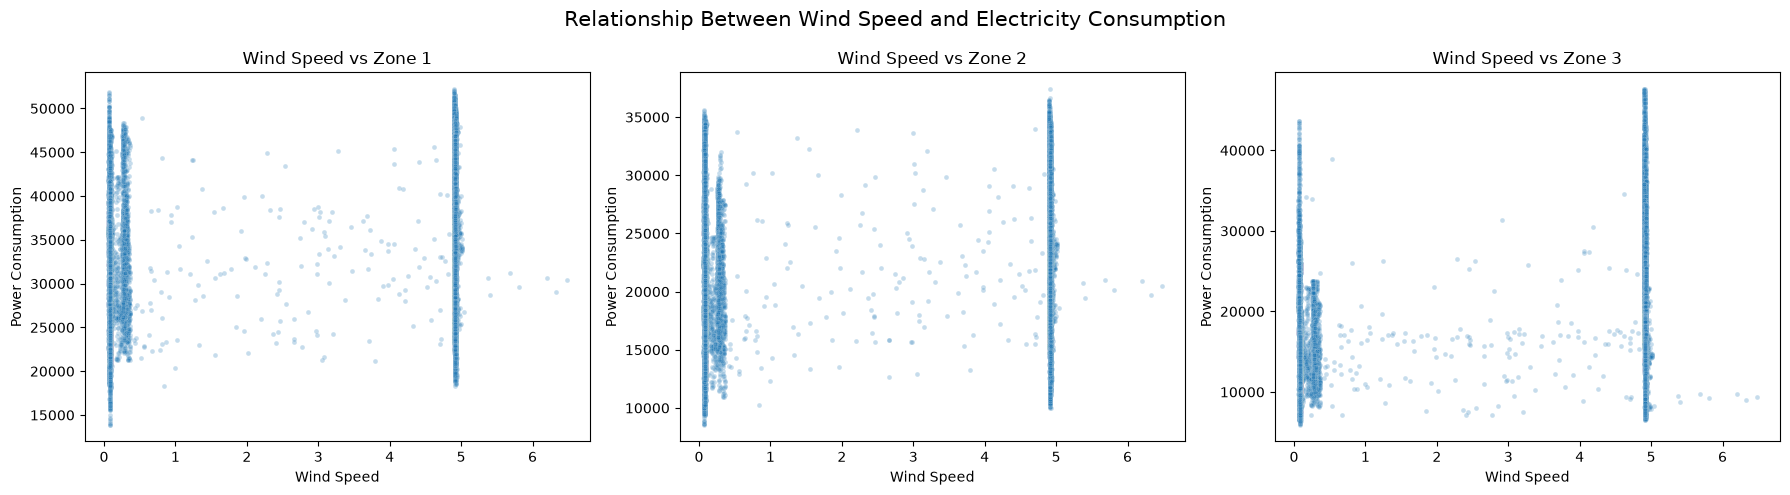

In [82]:
#### Wind speed and electricity consumption
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, zone, label in zip(axes, zones, zone_labels):
    sns.scatterplot(
        data=pc_analysis,
        x="WindSpeed",
        y=zone,
        alpha=0.25,
        s=12,
        ax=ax)

    ax.set_title(f"Wind Speed vs {label}")
    ax.set_xlabel("Wind Speed")
    ax.set_ylabel("Power Consumption")

plt.suptitle("Relationship Between Wind Speed and Electricity Consumption", fontsize=15)

plt.tight_layout()
plt.show()

In [83]:
#### Spearman correlation analysis
spearman_matrix = pc_analysis[correlation_columns].corr(method="spearman")

display(spearman_matrix.round(2))

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,1.00,-0.38,0.33,0.47,0.26,0.43,0.38,0.44
Humidity,-0.38,1.00,-0.18,-0.46,-0.25,-0.30,-0.31,-0.21
WindSpeed,0.33,-0.18,1.00,0.16,0.02,0.11,0.09,0.08
GeneralDiffuseFlows,0.47,-0.46,0.16,1.00,0.79,0.26,0.24,0.08
DiffuseFlows,0.26,-0.25,0.02,0.79,1.00,0.12,0.10,-0.02
PowerConsumption_Zone1,0.43,-0.30,0.11,0.26,0.12,1.00,0.85,0.75
PowerConsumption_Zone2,0.38,-0.31,0.09,0.24,0.10,0.85,1.00,0.54
PowerConsumption_Zone3,0.44,-0.21,0.08,0.08,-0.02,0.75,0.54,1.00


#### Pearson and Spearman Correlation — Comparative Findings

Pearson and Spearman correlation analyses generally show consistent positive relationships between temperature and electricity consumption, and negative relationships between humidity and consumption across all three zones.

Temperature shows the strongest environmental association with consumption. Zone 3 has the highest Pearson temperature correlation (0.49), while its Spearman correlation is 0.44.

Wind speed shows weaker and less consistent relationships. In Zone 3, its Pearson correlation is 0.28, compared with a Spearman correlation of 0.08. This difference suggests that the linear association may not reflect a consistent monotonic relationship.

The recorded GeneralDiffuseFlows variable has weak positive associations with consumption, while DiffuseFlows has very weak associations. The two flow variables have a Spearman correlation of 0.79.

These are observational associations. They do not demonstrate causality, and temporal patterns or other unmeasured factors may influence the results.

In [84]:
### Investigating temperature relationships by hour
hourly_temperature_correlations = (pc_analysis.groupby("Hour")
    .apply(lambda group: group[["Temperature"] + zone_columns].corr().loc["Temperature", zone_columns],
        include_groups=False))

hourly_temperature_correlations.columns = ["Zone 1", "Zone 2", "Zone 3"]

display(hourly_temperature_correlations.round(3))

,Zone 1,Zone 2,Zone 3
Hour,,,
0,0.652,0.573,0.599
1,0.636,0.597,0.596
2,0.585,0.597,0.582
3,0.692,0.644,0.593
4,0.773,0.630,0.576
5,0.402,0.187,0.292
6,0.325,0.081,0.236
7,0.572,0.339,0.544
8,0.586,0.430,0.648


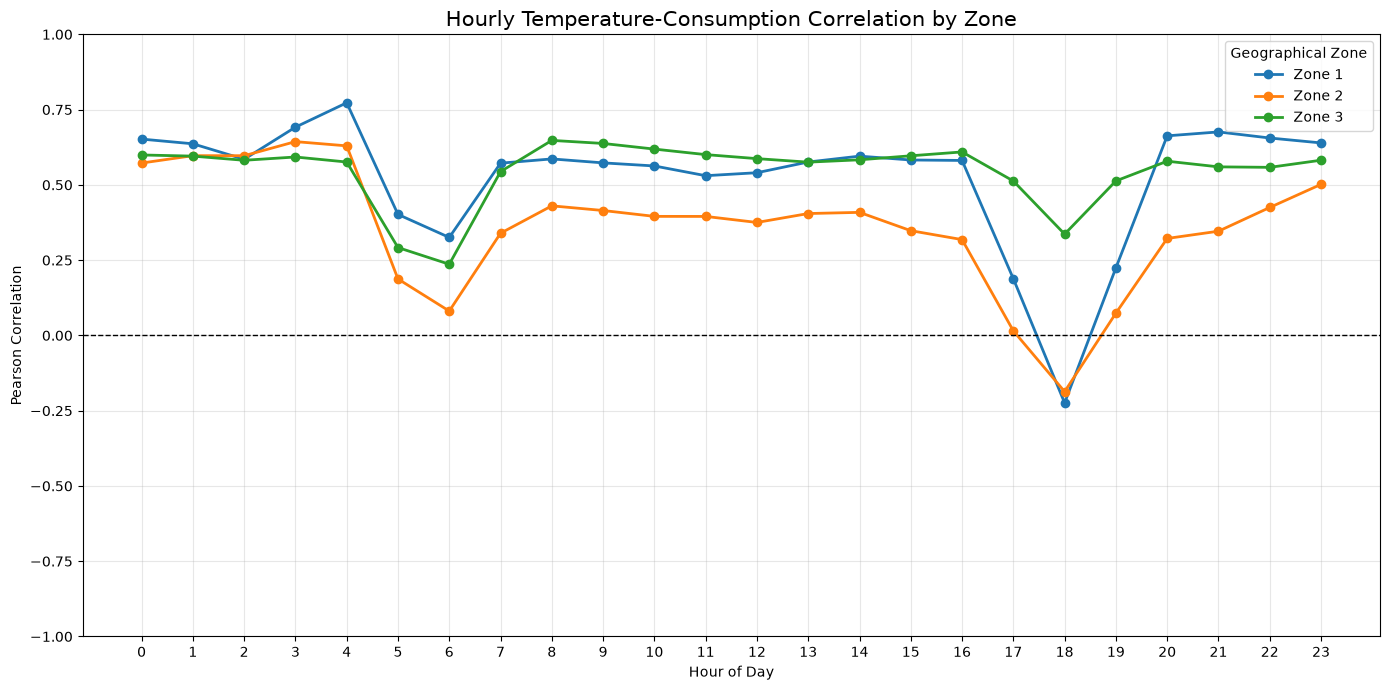

In [85]:
plt.figure(figsize=(14, 7))

for column in hourly_temperature_correlations.columns:
    plt.plot(
        hourly_temperature_correlations.index,
        hourly_temperature_correlations[column],
        marker="o",
        linewidth=2,
        label=column)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1)

plt.title("Hourly Temperature-Consumption Correlation by Zone", fontsize=15)

plt.xlabel("Hour of Day")
plt.ylabel("Pearson Correlation")
plt.xticks(range(24))
plt.ylim(-1, 1)
plt.legend(title="Geographical Zone")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [86]:
### Hourly correlation chart completed
hourly_humidity_correlations = (pc_analysis.groupby("Hour").apply(
        lambda group: group[
            ["Humidity"] + zone_columns].corr().loc["Humidity", zone_columns],
        include_groups=False))

hourly_humidity_correlations.columns = ["Zone 1", "Zone 2", "Zone 3"]

display(hourly_humidity_correlations.round(3))

,Zone 1,Zone 2,Zone 3
Hour,,,
0,-0.084,-0.168,-0.145
1,-0.067,-0.141,-0.143
2,-0.043,-0.115,-0.133
3,-0.080,-0.146,-0.174
4,-0.114,-0.180,-0.182
5,-0.088,-0.129,-0.192
6,-0.143,-0.153,-0.220
7,-0.076,-0.143,-0.201
8,-0.116,-0.156,-0.250


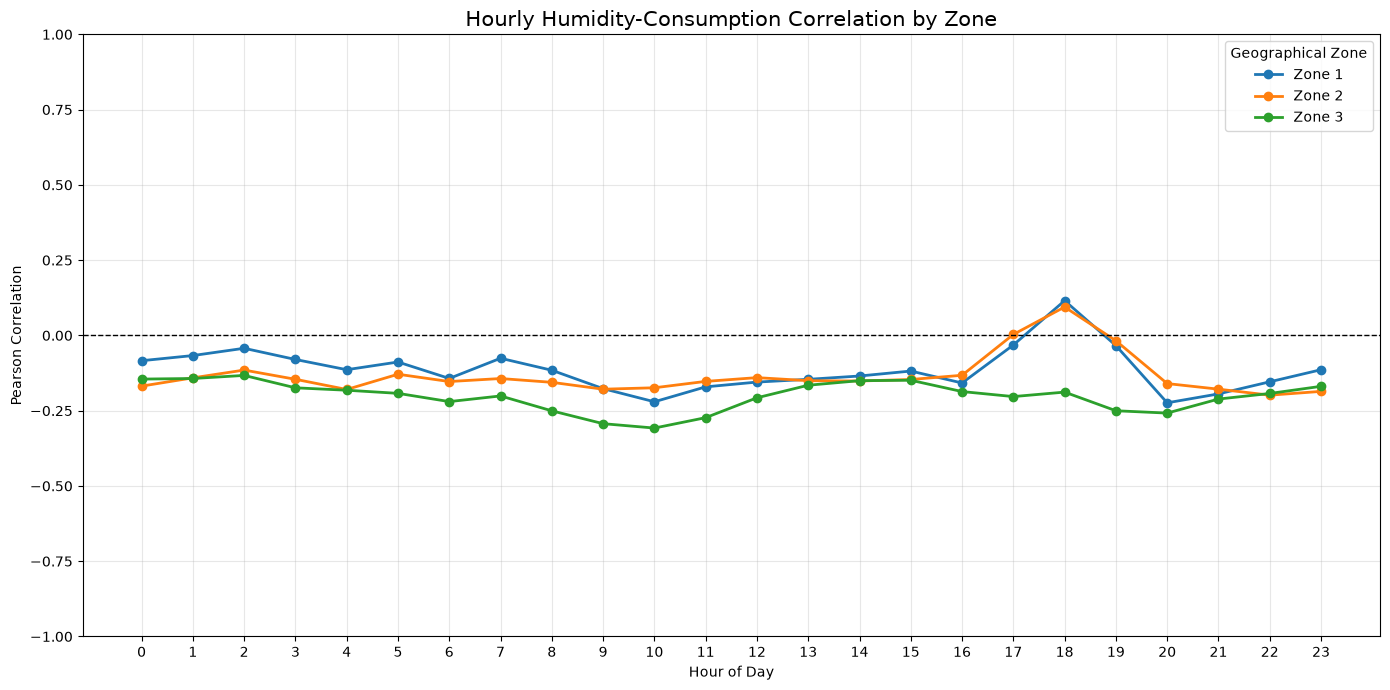

In [87]:
plt.figure(figsize=(14, 7))

for column in hourly_humidity_correlations.columns:
    plt.plot(
        hourly_humidity_correlations.index,
        hourly_humidity_correlations[column],
        marker="o",
        linewidth=2,
        label=column)

plt.axhline(y=0,
    color="black",
    linestyle="--",
    linewidth=1)

plt.title("Hourly Humidity-Consumption Correlation by Zone", fontsize=15)

plt.xlabel("Hour of Day")
plt.ylabel("Pearson Correlation")
plt.xticks(range(24))
plt.ylim(-1, 1)
plt.legend(title="Geographical Zone")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [88]:
### Hourly wind-speed consumption correlations
hourly_wind_correlations = (pc_analysis.groupby("Hour").apply(
        lambda group: group[
            ["WindSpeed"] + zone_columns].corr().loc["WindSpeed", zone_columns],
        include_groups=False))

hourly_wind_correlations.columns = ["Zone 1", "Zone 2", "Zone 3"]

display(hourly_wind_correlations.round(3))

,Zone 1,Zone 2,Zone 3
Hour,,,
0,0.392,0.357,0.408
1,0.346,0.340,0.387
2,0.270,0.303,0.350
3,0.369,0.356,0.385
4,0.467,0.382,0.396
5,0.315,0.160,0.288
6,0.288,0.101,0.271
7,0.351,0.233,0.403
8,0.344,0.306,0.411


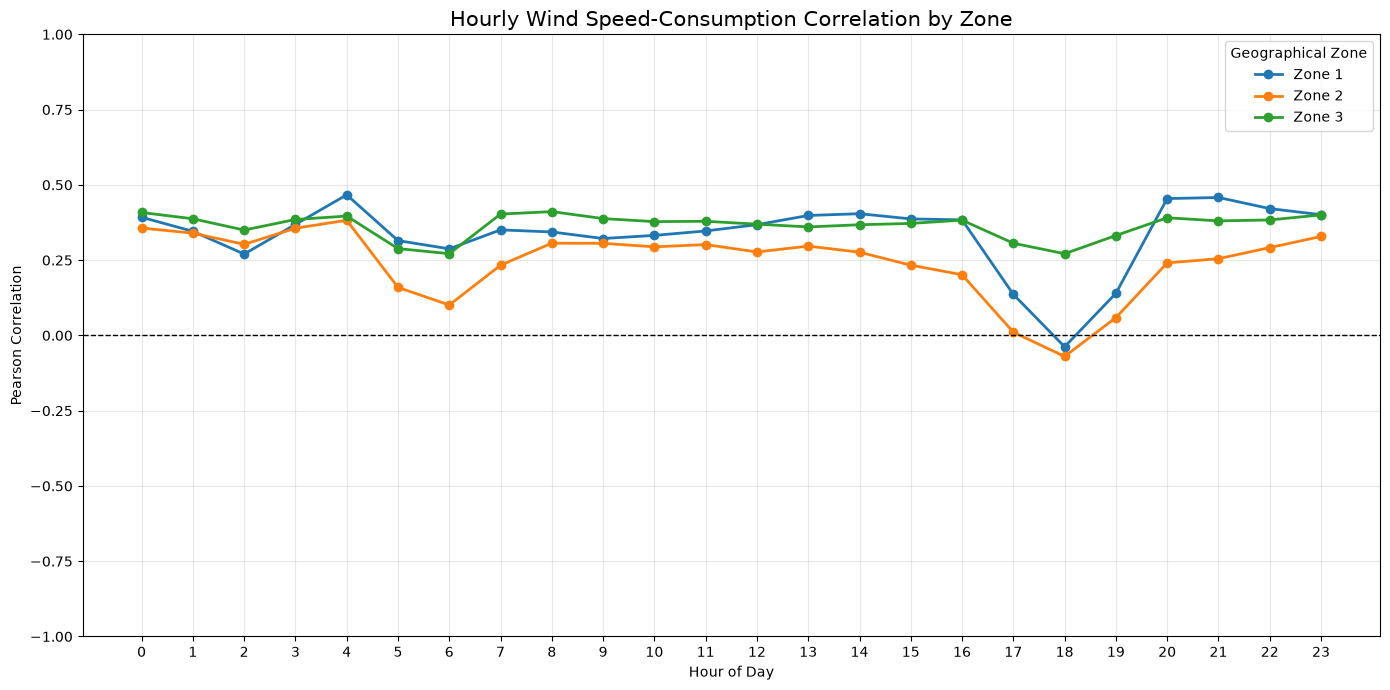

In [89]:
plt.figure(figsize=(14, 7))

for column in hourly_wind_correlations.columns:
    plt.plot(
        hourly_wind_correlations.index,
        hourly_wind_correlations[column],
        marker="o",
        linewidth=2,
        label=column)

plt.axhline(y=0,
    color="black",
    linestyle="--",
    linewidth=1)

plt.title("Hourly Wind Speed-Consumption Correlation by Zone", fontsize=15)

plt.xlabel("Hour of Day")
plt.ylabel("Pearson Correlation")
plt.xticks(range(24))
plt.ylim(-1, 1)
plt.legend(title="Geographical Zone")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Environmental Relationship Analysis — Summary of Findings

##### Overall environmental relationships

Pearson correlation analysis identified the following relationships between environmental measurements and electricity consumption:

| Environmental variable | Zone 1 | Zone 2 | Zone 3 |
|---|---:|---:|---:|
| Temperature | 0.44 | 0.38 | 0.49 |
| Humidity | -0.29 | -0.29 | -0.23 |
| Wind speed | 0.17 | 0.15 | 0.28 |
| GeneralDiffuseFlows | 0.19 | 0.16 | 0.06 |
| DiffuseFlows | 0.08 | 0.04 | -0.04 |

Temperature showed the strongest positive environmental association with consumption across all three zones. Humidity showed negative associations, while wind speed showed weaker positive associations.

##### Pearson and Spearman comparison

The Pearson and Spearman results generally agreed on the direction of the temperature and humidity relationships.

However, wind speed showed differences between the two methods, particularly in Zone 3, where Pearson correlation was 0.28 and Spearman correlation was 0.08.

This suggests that the observed linear association may not represent a consistently increasing rank relationship.

##### Hourly relationship analysis

Hourly correlation analysis revealed that environmental relationships with electricity consumption vary throughout the day.

- Temperature correlations were generally positive, but became negative for Zones 1 and 2 at 18:00.
- Humidity correlations were generally negative, with slight positive relationships for Zones 1 and 2 at 18:00.
- Wind speed correlations were generally positive, although Zones 1 and 2 recorded negative relationships at 18:00.

Zone 3 maintained positive hourly temperature and wind-speed correlations throughout the day, while its humidity correlations remained negative.

##### Business relevance

The findings suggest that environmental relationships should be evaluated alongside time-of-day patterns rather than treated as constant across the day.

Energy planners could use these observations to identify periods and geographical zones that warrant closer monitoring. The findings may also guide future demand-modelling investigations.

####  Analytical limitations

- Correlation does not establish causation.
- Time-of-day and seasonal patterns may influence both environmental measurements and electricity consumption.
- The analysis does not control for all possible confounding variables.
- The physical definitions and measurement units of the diffuse-flow variables require confirmation.
- The dataset covers 2017 only, limiting conclusions about long-term patterns.
- The results should not be used alone to make operational or investment decisions.

**Conclusion:** Environmental variables exhibit different strengths and directions of association with electricity consumption across geographical zones and hours. Temperature has the strongest overall environmental association, while hourly analysis demonstrates that these relationships are time-dependent.

#### Key Business Findings

The following findings summarise the most important patterns identified during the exploratory analysis of Morocco's electricity consumption dataset.

| No. | Business finding | Supporting evidence | Business relevance |
|---|---|---|---|
| 1 | Zone 1 records the highest average electricity consumption. | Zone 1: 32,344.97; Zone 2: 21,042.51; Zone 3: 17,835.41. | Zone 1 deserves particular attention when comparing consumption levels and monitoring operational demand. |
| 2 | All three zones experience their highest average hourly consumption at 20:00. | Zone 1: 43,822.59; Zone 2: 28,186.91; Zone 3: 26,027.61. | The 20:00 period is a useful priority for peak-demand monitoring and operational planning. |
| 3 | Consumption patterns differ across the months and geographical zones. | Zone 1 and Zone 2 reach their highest monthly averages in August, while Zone 3 peaks in July. | Planning should account for differences in monthly consumption patterns rather than assuming identical behaviour across zones. |
| 4 | Zone 3 has the lowest average consumption but records the highest individual consumption maximum among the zones. | Zone 3 maximum: 47,598.33; Zone 1 maximum: 52,204.40; Zone 2 maximum: 37,408.86. | Average consumption alone may not adequately describe the range of demand experienced by each zone. |
| 5 | Temperature has the strongest overall environmental association with electricity consumption. | Pearson correlations: Zone 1 = 0.44; Zone 2 = 0.38; Zone 3 = 0.49. | Temperature is a useful variable to investigate in future demand-monitoring and forecasting models. |
| 6 | Environmental relationships change throughout the day. | At 18:00, temperature correlations are negative for Zones 1 and 2, while Zone 3 remains positive. | Hourly analysis may provide more useful insights than relying exclusively on overall correlation values. |
| 7 | Consumption readings across the geographical zones move together, particularly Zones 1 and 2. | Pearson correlation between Zone 1 and Zone 2 = 0.83. | Monitoring multiple zones together may help identify shared consumption patterns. |

##### Business interpretation

The analysis identifies Zone 1 as the largest contributor to recorded consumption, 20:00 as the common peak hour, and meaningful differences in monthly and environmental patterns across the three zones.

These findings provide a basis for more focused monitoring, further investigation, and demand-planning activities. They should be treated as exploratory evidence rather than proof of the causes of electricity consumption patterns.

#### Business Recommendations

Based on the exploratory analysis of Morocco's electricity consumption dataset, the following recommendations are proposed to support improved monitoring, operational planning, and future energy-management decisions.

##### Recommendation 1: Strengthen peak-period demand monitoring

**Finding:** All three geographical zones recorded their highest average hourly consumption at 20:00.

**Recommended action:** Prioritise monitoring of electricity demand around the evening peak period, particularly between 19:00 and 21:00. Investigate whether existing operational schedules and demand-management arrangements adequately account for this period.

**Expected business benefit:** Improved visibility of peak-demand patterns, better operational preparedness, and more informed demand-management planning.

**Limitation:** The analysis identifies a recurring hourly pattern but does not establish the causes of peak demand or confirm available generation and distribution capacity.

##### Recommendation 2: Develop zone-specific monitoring strategies

**Finding:** Zone 1 has the highest average consumption (32,344.97), while Zone 3 has the lowest average (17,835.41). Monthly and weekly patterns also differ between zones.

**Recommended action:** Develop separate monitoring indicators for each geographical zone rather than relying exclusively on organisation-wide averages. Investigate the operational and demographic factors that may explain differences between zones.

**Expected business benefit:** More targeted monitoring, improved identification of unusual consumption patterns, and better-informed resource-planning discussions.

**Limitation:** The dataset does not provide sufficient information about population, customer numbers, industrial activity, or infrastructure capacity to explain the differences or establish efficiency rankings.

##### Recommendation 3: Incorporate environmental variables into future demand-modelling investigations

**Finding:** Temperature has the strongest overall environmental correlation with electricity consumption, with Pearson coefficients of 0.44, 0.38, and 0.49 for Zones 1, 2, and 3 respectively.

**Recommended action:** Evaluate temperature alongside humidity, wind speed, time of day, and seasonal patterns when developing future electricity-demand forecasting models.

**Expected business benefit:** A more comprehensive understanding of consumption patterns and the potential to improve forecasting performance.

**Limitation:** Correlation does not establish causation. Model performance must be independently evaluated using appropriate training and testing periods before operational adoption.

##### Recommendation 4: Investigate unusual consumption peaks

**Finding:** Zone 3 recorded unusually high consumption readings during July, particularly around 23–27 July 2017. Zone 1 also recorded the highest absolute individual consumption reading among the three zones.

**Recommended action:** Investigate selected high-consumption periods against operational records, historical demand reports, and available infrastructure information to determine whether they represent genuine demand events or data-quality issues.

**Expected business benefit:** Better understanding of exceptional demand periods and improved monitoring of potential operational anomalies.

**Limitation:** Statistical outliers are not necessarily errors. The current dataset alone cannot establish the causes of these readings.

##### Recommendation 5: Improve the organisation's analytical data infrastructure

**Finding:** The analysis covers one year of observations, and the measurement units and physical definitions of some recorded environmental variables require further confirmation.

**Recommended action:** Maintain consistent historical electricity and environmental records, verify measurement definitions and units, and extend the dataset across additional years where available.

**Expected business benefit:** More reliable comparisons over time, stronger forecasting investigations, and improved confidence in future analytical outputs.

**Limitation:** Additional historical data and verified metadata may require investment in data collection, integration, and quality-control processes.

##### Overall recommendation

The organisation should prioritise evening peak-demand monitoring, develop zone-specific monitoring practices, and strengthen its environmental demand-modelling investigations. These activities should be supported by verified operational information and additional historical data before major infrastructure or investment decisions are made.

In [91]:
#### Prepare the output folders
from pathlib import Path

project_root = Path("..")

output_folders = [project_root / "visualizations" / "static",
    project_root / "visualizations" / "interactive",
    project_root / "reports",
    project_root / "documentation"]

for folder in output_folders:
    folder.mkdir(parents=True, exist_ok=True)

print("Project output folders verified successfully!")

for folder in output_folders:
    print(folder)

Project output folders verified successfully!
..\visualizations\static
..\visualizations\interactive
..\reports
..\documentation


In [92]:
#### Exporting static visualisations

static_dir = Path("../visualizations/static")
static_dir.mkdir(parents=True, exist_ok=True)

##### 1. Average consumption by zone
plt.figure(figsize=(10, 6))
sns.barplot(
    x=["Zone 1", "Zone 2", "Zone 3"],
    y=[pc_analysis["PowerConsumption_Zone1"].mean(),
        pc_analysis["PowerConsumption_Zone2"].mean(),
        pc_analysis["PowerConsumption_Zone3"].mean()])

plt.title("Average Electricity Consumption by Zone")
plt.xlabel("Geographical Zone")
plt.ylabel("Average Recorded Consumption")
plt.tight_layout()
plt.savefig(static_dir / "average_consumption_by_zone.png", dpi=300)
plt.close()

##### 2. Hourly consumption
plt.figure(figsize=(12, 6))
for column, label in zip(zone_columns, zone_labels):
    plt.plot(hourly_consumption.index, hourly_consumption[column], label=label)

plt.title("Average Hourly Electricity Consumption by Zone")
plt.xlabel("Hour of Day")
plt.ylabel("Average Recorded Consumption")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(static_dir / "hourly_consumption_by_zone.png", dpi=300)
plt.close()

##### 3. Monthly consumption
plt.figure(figsize=(13, 6))
monthly_consumption.plot(kind="line", marker="o", figsize=(13, 6))
plt.title("Monthly Average Electricity Consumption by Zone")
plt.xlabel("Month")
plt.ylabel("Average Recorded Consumption")
plt.xticks(range(12), monthly_consumption.index, rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(static_dir / "monthly_consumption_by_zone.png", dpi=300)
plt.close()

##### 4. Monthly consumption heatmap
plt.figure(figsize=(13, 5))
sns.heatmap(
    monthly_consumption.T,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5)

plt.title("Monthly Average Consumption Heatmap")
plt.xlabel("Month")
plt.ylabel("Geographical Zone")
plt.tight_layout()
plt.savefig(static_dir / "monthly_consumption_heatmap.png", dpi=300)
plt.close()

##### 5. Correlation heatmap
plt.figure(figsize=(13, 9))
sns.heatmap(correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5)

plt.title("Environmental and Electricity Consumption Correlation")
plt.tight_layout()
plt.savefig(static_dir / "correlation_heatmap.png", dpi=300)
plt.close()

print("Static visualisations exported successfully!")

for file in static_dir.glob("*.png"):
    print(file.name)

Static visualisations exported successfully!
average_consumption_by_zone.png
correlation_heatmap.png
hourly_consumption_by_zone.png
monthly_consumption_by_zone.png
monthly_consumption_heatmap.png


<Figure size 1300x600 with 0 Axes>

In [93]:
static_dir = Path("../visualizations/static")

for file in sorted(static_dir.glob("*.png")):
    print(f"{file.name} | "
        f"Exists: {file.exists()} | "
        f"Size: {file.stat().st_size / 1024:.2f} KB")

print("\nTotal exported images:", len(list(static_dir.glob("*.png"))))

average_consumption_by_zone.png | Exists: True | Size: 84.26 KB
correlation_heatmap.png | Exists: True | Size: 344.90 KB
hourly_consumption_by_zone.png | Exists: True | Size: 249.78 KB
monthly_consumption_by_zone.png | Exists: True | Size: 274.90 KB
monthly_consumption_heatmap.png | Exists: True | Size: 242.79 KB

Total exported images: 5


In [94]:
#### Exporting interactive visualisations
import plotly.graph_objects as go

interactive_dir = Path("../visualizations/interactive")
interactive_dir.mkdir(parents=True, exist_ok=True)

# 1. Interactive hourly consumption chart
fig_hourly = go.Figure()

zone_labels = ["Zone 1", "Zone 2", "Zone 3"]

for column, label in zip(zone_columns, zone_labels):
    fig_hourly.add_trace(
        go.Scatter(
            x=hourly_consumption.index,
            y=hourly_consumption[column],
            mode="lines+markers",
            name=label,
            hovertemplate=(
                "Hour: %{x}:00<br>"
                "Average recorded consumption: %{y:,.2f}"
                "<extra>%{fullData.name}</extra>")))

fig_hourly.update_layout(title="Interactive Hourly Electricity Consumption by Zone",
    xaxis_title="Hour of Day",
    yaxis_title="Average Recorded Consumption",
    xaxis=dict(tickmode="linear", dtick=1),
    hovermode="x unified",
    template="plotly_white")

fig_hourly.write_html(interactive_dir / "hourly_consumption_by_zone.html", include_plotlyjs=True)


# 2. Interactive monthly consumption chart
fig_monthly = go.Figure()

for column, label in zip(zone_columns, zone_labels):
    fig_monthly.add_trace(
        go.Scatter(
            x=monthly_consumption.index,
            y=monthly_consumption[column],
            mode="lines+markers",
            name=label,
            hovertemplate=(
                "Month: %{x}<br>"
                "Average recorded consumption: %{y:,.2f}"
                "<extra>%{fullData.name}</extra>")))

fig_monthly.update_layout(title="Interactive Monthly Electricity Consumption by Zone",
    xaxis_title="Month",
    yaxis_title="Average Recorded Consumption",
    hovermode="x unified",
    template="plotly_white")

fig_monthly.write_html(interactive_dir / "monthly_consumption_by_zone.html",include_plotlyjs=True)

print("Interactive visualisations exported successfully!")

Interactive visualisations exported successfully!


In [95]:
for file in sorted(interactive_dir.glob("*.html")):
    print(f"{file.name} | "
        f"Exists: {file.exists()} | "
        f"Size: {file.stat().st_size / 1024:.2f} KB")

print("\nTotal interactive visualisations:",
      len(list(interactive_dir.glob("*.html"))))

hourly_consumption_by_zone.html | Exists: True | Size: 4715.89 KB
monthly_consumption_by_zone.html | Exists: True | Size: 4715.32 KB

Total interactive visualisations: 2


In [96]:
#### Create the project documentation

documentation_dir = Path("../documentation")
documentation_dir.mkdir(parents=True, exist_ok=True)

documents = {
    "initial_data_quality_assessment.md": """
# Initial Data Quality Assessment

## Project
Morocco Electricity Consumption Analysis

## Dataset Overview
- Records: 52,416
- Columns: 9
- Coverage: 1 January 2017 to 30 December 2017
- Recording frequency: 10 minutes
- Recorded days: 364
- Expected observations per recorded day: 144

## Data Quality Checks

| Check | Result |
|---|---|
| Missing values | None identified |
| Duplicate timestamps | None identified |
| Exact duplicate rows | None identified |
| Invalid datetime values | None identified |
| Chronological ordering | Confirmed |
| Irregular recording intervals | None identified |
| Incomplete recorded days | None identified |
| Negative numerical values | None identified |
| Missing calendar dates within the covered range | None identified |

## Coverage Limitation
The dataset ends on 30 December 2017. No observation for 31 December 2017 is present. The reason for this absence is unknown and should not be assumed.

## Initial Assessment
The dataset passed the checks listed above and was suitable for the planned descriptive analysis. These checks do not establish that every measurement is accurate or that all variable definitions and units are fully understood.
""",

    "data_preparation_log.md": """
# Data Preparation Log

## Project
Morocco Electricity Consumption Analysis

## Preparation Steps

1. Loaded the original CSV dataset into Pandas.
2. Preserved the imported data in its original form and created a separate working copy for analysis.
3. Converted the Datetime field to a datetime data type.
4. Checked for invalid dates, duplicate timestamps and chronological ordering.
5. Verified the 10-minute recording interval and daily observation counts.
6. Checked missing values, exact duplicate rows and negative numerical values.
7. Used the interquartile range (IQR) method to flag potential statistical outliers.
8. Investigated unusually high consumption readings, including elevated Zone 3 readings in July.
9. Retained flagged outliers because statistical flags alone do not establish measurement errors.
10. Created temporal features including Year, Month, Month_Name, Day, Hour, Day_of_Week, Day_Name and Is_Weekend.
11. Created a standardized Date field for daily aggregation.
12. Saved the prepared dataset as `data/processed/morocco_electricity_prepared.csv`.

## Outlier Treatment Decision
Potential outliers were retained in the analytical dataset. Removing or modifying extreme observations without supporting evidence could remove genuine high-demand periods and distort the analysis.

## Output
Prepared dataset: `data/processed/morocco_electricity_prepared.csv`
""",

    "methodology_and_limitations.md": """
# Analytical Methodology and Limitations

## Analytical Approach
The project uses Python-based exploratory data analysis to examine electricity consumption across three geographical zones and explore relationships with recorded environmental variables.

## Tools and Libraries
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Plotly
- SciPy and Statsmodels, where applicable

## Analysis Methods
- Descriptive statistics: mean, median, minimum, maximum and standard deviation.
- Temporal aggregation: hourly, daily, weekly and monthly averages.
- Zone comparison: grouped summaries, bar charts, boxplots and heatmaps.
- Environmental analysis: Pearson and Spearman correlation.
- Outlier screening: interquartile range (IQR).
- Visualisation: static Matplotlib/Seaborn charts and interactive Plotly charts.

## Important Limitations

### Measurement Units
The data dictionary describes consumption in kWh, but the exact measurement convention for each 10-minute observation has not been independently confirmed. Therefore, this analysis refers to recorded consumption readings and does not assume that summing the readings produces verified total energy consumption.

### Environmental Variable Definitions
The precise physical definitions and units of `GeneralDiffuseFlows` and `DiffuseFlows` require confirmation from the data provider. Their physical meaning should not be inferred from their names alone.

### Correlation and Causation
Pearson and Spearman correlations identify statistical associations. They do not demonstrate that environmental conditions cause changes in electricity consumption. Time of day, seasonality and other potential confounding factors may influence observed relationships.

### Time Coverage
The dataset covers 1 January to 30 December 2017. It does not contain 31 December 2017 or multiple years of observations. Findings should not be treated as evidence of long-term trends.

### Outliers
IQR flags identify values outside statistical thresholds, not necessarily erroneous measurements. Flagged values were retained unless there was evidence that they were invalid.

### Contextual Data
The dataset does not provide sufficient information about population, customer numbers, installed capacity, tariffs or operational conditions to explain why zones differ or to establish comparative efficiency.

## Interpretation Principle
All findings are descriptive and should be interpreted within the coverage, definitions and limitations of the available dataset.
""",

    "key_findings_and_recommendations.md": """
# Key Findings and Business Recommendations

## Key Findings

1. Zone 1 recorded the highest mean consumption reading at approximately 32,344.97, followed by Zone 2 at 21,042.51 and Zone 3 at 17,835.41.
2. All three zones recorded their highest average hourly readings at 20:00.
3. Zone 1 and Zone 2 recorded their highest monthly averages in August, while Zone 3 peaked in July.
4. Zone 3 had the lowest mean but a maximum reading of approximately 47,598.33. This indicates that its distribution includes some high readings relative to its average.
5. Temperature showed positive Pearson correlations with consumption in all three zones: 0.44 for Zone 1, 0.38 for Zone 2 and 0.49 for Zone 3.
6. Humidity showed negative Pearson correlations with consumption in all three zones.
7. Consumption readings across zones were positively correlated, particularly between Zone 1 and Zone 2 (Pearson correlation of approximately 0.83).

## Recommendations

### 1. Monitor Evening Demand
**Action:** Prioritise monitoring around the observed evening peak, particularly 19:00–21:00.

**Potential benefit:** Helps the organisation investigate recurring high-demand periods and support operational planning.

**Limitation:** The dataset does not establish the causes of the evening peak or confirm available generation and network capacity.

### 2. Use Zone-Specific Monitoring
**Action:** Track consumption patterns separately for each geographical zone.

**Potential benefit:** Supports identification of differences in demand profiles and more targeted investigation.

**Limitation:** Differences in readings do not establish differences in efficiency, population or infrastructure capacity.

### 3. Investigate Environmental Relationships
**Action:** Consider temperature and humidity as candidate explanatory variables in future demand-forecasting work.

**Potential benefit:** May help improve understanding of patterns and support forecasting research.

**Limitation:** Correlation does not establish causation. Any forecasting model should be tested on separate, unseen time periods.

### 4. Investigate Unusual High-Consumption Periods
**Action:** Review the elevated Zone 3 readings observed around 23–27 July 2017, especially around 19:50–20:20.

**Potential benefit:** Could help determine whether these periods reflect genuine demand peaks, operational events or measurement issues.

**Limitation:** The available dataset does not identify the cause. These readings should not automatically be classified as errors.

### 5. Improve Data Documentation
**Action:** Confirm measurement units, interval conventions and environmental variable definitions with the data provider. Where possible, obtain additional years and relevant operational context.

**Potential benefit:** Improves interpretability, comparability and the reliability of future analysis.

**Limitation:** Additional data and metadata may require further collection and validation.

## Conclusion
The analysis identifies meaningful differences in consumption patterns across the three zones, a shared evening peak and statistical associations between consumption and selected environmental variables. These findings can guide further investigation and planning, but operational decisions should be supported by validated measurement definitions and additional contextual data.
"""
}

for filename, content in documents.items():
    file_path = documentation_dir / filename
    file_path.write_text(content.strip() + "\n", encoding="utf-8")
    print(f"Created: {file_path.name}")

print("\nDocumentation files created:", len(documents))

Created: initial_data_quality_assessment.md
Created: data_preparation_log.md
Created: methodology_and_limitations.md
Created: key_findings_and_recommendations.md

Documentation files created: 4


In [97]:
### Create the executive summary
reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

executive_summary = """
# Executive Summary
## Morocco Electricity Consumption Analysis

### 1. Project Overview

This project examines electricity consumption readings across three geographical zones in Morocco using Python-based exploratory data analysis and visualisation.

The analysis investigates differences between zones, hourly and monthly patterns, and statistical relationships between recorded environmental variables and electricity consumption.

### 2. Dataset Overview

The dataset contains 52,416 observations and nine original columns, covering 1 January to 30 December 2017 at 10-minute intervals.

Data preparation included datetime validation, missing-value checks, duplicate checks, interval verification, outlier investigation and the creation of temporal features.

No missing values, duplicate timestamps, exact duplicate rows, invalid datetime values, irregular recording intervals or negative numerical values were identified during the reported quality checks.

Potential statistical outliers were retained because they could represent genuine demand patterns rather than data errors.

### 3. Key Findings

**Differences between geographical zones**

- Zone 1 recorded the highest mean consumption reading: approximately 32,344.97.
- Zone 2 followed at approximately 21,042.51.
- Zone 3 recorded the lowest mean at approximately 17,835.41.

**Hourly demand patterns**

All three zones recorded their highest average hourly readings at 20:00:

- Zone 1: approximately 43,822.59.
- Zone 2: approximately 28,186.91.
- Zone 3: approximately 26,027.61.

This shared evening peak provides a useful focus for further demand monitoring.

**Monthly patterns**

- Zone 1 recorded its highest monthly average in August.
- Zone 2 also recorded its highest monthly average in August.
- Zone 3 recorded its highest monthly average in July.

The monthly patterns were not identical across the three zones.

**Environmental relationships**

Temperature had positive Pearson correlations with consumption in all three zones:

- Zone 1: 0.44.
- Zone 2: 0.38.
- Zone 3: 0.49.

Humidity had negative Pearson correlations with consumption across all three zones. These results describe statistical associations and do not establish causal relationships.

### 4. Business Recommendations

1. Prioritise monitoring of the observed evening demand peak, particularly between 19:00 and 21:00.
2. Maintain zone-specific monitoring to identify differences in consumption patterns.
3. Investigate temperature and humidity as potential variables in future demand-forecasting models.
4. Review unusually high Zone 3 readings observed around 23–27 July 2017 to establish whether they reflect genuine demand or measurement issues.
5. Improve data documentation by confirming measurement units, interval conventions and environmental variable definitions.

### 5. Limitations

The dataset covers one year of observations and does not include 31 December 2017. The exact measurement convention for each 10-minute consumption reading has not been independently confirmed.

The definitions and units of GeneralDiffuseFlows and DiffuseFlows also require clarification.

The analysis is descriptive. It does not establish causation, explain the underlying reasons for zone differences, or prove that one zone is more energy-efficient than another.

### 6. Conclusion

The analysis identifies differences in consumption across the three geographical zones, a common evening peak and relationships between consumption and selected environmental variables.

These findings provide a starting point for more detailed demand monitoring and forecasting research. Stronger operational conclusions will require confirmed measurement definitions, additional years of data and relevant infrastructure and operational context.

### 7. Tools Used

Python, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn and Plotly.
"""

summary_path = reports_dir / "executive_summary.md"
summary_path.write_text(executive_summary.strip() + "\n", encoding="utf-8")

print("Executive summary created:", summary_path.name)
print("File exists:", summary_path.exists())
print("File size:", round(summary_path.stat().st_size / 1024, 2), "KB")

Executive summary created: executive_summary.md
File exists: True
File size: 3.86 KB


In [99]:
from pathlib import Path

project_dir = Path("..")

files_to_check = [
    project_dir / "data/raw/powerconsumption.csv",
    project_dir / "data/raw/powerconsumption_datadictionary.csv",
    project_dir / "data/processed/morocco_electricity_prepared.csv"
]

for file in files_to_check:
    print(f"\nFile: {file.name}")
    print(f"Exists: {file.exists()}")

    if file.exists():
        print(f"Size: {file.stat().st_size / (1024 * 1024):.2f} MB")


File: powerconsumption.csv
Exists: True
Size: 4.03 MB

File: powerconsumption_datadictionary.csv
Exists: True
Size: 0.00 MB

File: morocco_electricity_prepared.csv
Exists: True
Size: 6.60 MB


In [100]:
dictionary_path = Path("../data/raw/powerconsumption_datadictionary.csv")

print("File size in bytes:", dictionary_path.stat().st_size)

data_dictionary_check = pd.read_csv(dictionary_path)

print("\nData dictionary contents:")
display(data_dictionary_check)

print("\nShape:", data_dictionary_check.shape)
print("\nEmpty file:", data_dictionary_check.empty)

File size in bytes: 650

Data dictionary contents:


,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...



Shape: (9, 2)

Empty file: False


In [101]:
prepared_path = Path("../data/processed/morocco_electricity_prepared.csv")

prepared_check = pd.read_csv(prepared_path)

print("Prepared dataset shape:", prepared_check.shape)

print("\nFirst five rows:")
display(prepared_check.head())

print("\nMissing values:", prepared_check.isnull().sum().sum())

print("\nDuplicate rows:", prepared_check.duplicated().sum())

print("\nColumns:")
print(prepared_check.columns.tolist())

Prepared dataset shape: (52416, 18)

First five rows:


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Month_Name,Day,Hour,Day_of_Week,Day_Name,Is_Weekend,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,January,1,0,7,Sunday,True,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,January,1,0,7,Sunday,True,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,January,1,0,7,Sunday,True,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,January,1,0,7,Sunday,True,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,January,1,0,7,Sunday,True,2017-01-01



Missing values: 0

Duplicate rows: 0

Columns:
['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3', 'Year', 'Month', 'Month_Name', 'Day', 'Hour', 'Day_of_Week', 'Day_Name', 'Is_Weekend', 'Date']


In [102]:
project_dir = Path("..")

files_to_check = [
    project_dir / "notebooks/Morocco_Electricity_Analysis.ipynb",
    project_dir / "requirements.txt",
    project_dir / ".gitignore",
    project_dir / "README.md"
]

for file in files_to_check:
    print(f"\nFile: {file.name}")
    print("Exists:", file.exists())

    if file.exists():
        print("Size:", round(file.stat().st_size / 1024, 2), "KB")


File: Morocco_Electricity_Analysis.ipynb
Exists: True
Size: 3234.8 KB

File: requirements.txt
Exists: True
Size: 2.24 KB

File: .gitignore
Exists: True
Size: 0.29 KB

File: README.md
Exists: True
Size: 4.0 KB


In [103]:
static_dir = Path("../visualizations/static")
interactive_dir = Path("../visualizations/interactive")

static_files = list(static_dir.glob("*.png"))
interactive_files = list(interactive_dir.glob("*.html"))

print("STATIC VISUALISATIONS")
for file in sorted(static_files):
    print(f"{file.name} | {file.stat().st_size / 1024:.2f} KB")

print("\nINTERACTIVE VISUALISATIONS")
for file in sorted(interactive_files):
    print(f"{file.name} | {file.stat().st_size / 1024:.2f} KB")

print("\nTOTAL STATIC:", len(static_files))
print("TOTAL INTERACTIVE:", len(interactive_files))
print("TOTAL VISUALISATIONS:", len(static_files) + len(interactive_files))

STATIC VISUALISATIONS
average_consumption_by_zone.png | 84.26 KB
correlation_heatmap.png | 344.90 KB
hourly_consumption_by_zone.png | 249.78 KB
monthly_consumption_by_zone.png | 274.90 KB
monthly_consumption_heatmap.png | 242.79 KB

INTERACTIVE VISUALISATIONS
hourly_consumption_by_zone.html | 4715.89 KB
monthly_consumption_by_zone.html | 4715.32 KB

TOTAL STATIC: 5
TOTAL INTERACTIVE: 2
TOTAL VISUALISATIONS: 7
